# Week 2: the V-shaped error of finite differences, the optimal step, and the bulk modulus of Cu

Tasks 0–4 of the week 2 assignment; [`../README.md`](../README.md) summarizes the tasks and results.

| File | Contents |
|---|---|
| `floating_point.py` | Task 0: ε by a loop; direct and rewritten forms of (1 − cos x)/x² and of the small root of a quadratic |
| `finite_diff.py` | Tasks 1–2: D₊, D₋, D₀, D₃, D², D₅ (Richardson and the five-point formula), complex step; the error model computed from the stencil (order, truncation coefficient, round-off coefficient), the exact truncation-error series, the optimal-step formula |
| `debye_energy.py` | Task 3: the integrand of U(T) (handles x → 0 and overflow), U(T); series solutions for U, C_V and dC_V/dT without quadrature. Simpson's rule and C_V are reused from week 1 (`week01/work`) |
| `morse.py` | Task 4: Morse potential and its derivatives, FCC neighbour list, E⁽ⁿ⁾(a), a₀, B, the exact truncation error of D², noise, E(a) with the neighbours re-selected at every call |
| `test_*.py` | Automated tests (88) |
| `figures/` | `fig1_vshape.png`, `fig2_higher.png`, `fig3_debye_dUdT.png`, `fig4_bulk_modulus.png` |

**Run:** `conda activate cms`, then in `week02/work` run `pytest -q` and `jupyter lab lab02.ipynb` → Run All. Task 3 imports week 1's `quadrature.py` and `debye.py` from `../../week01/work`, so the two weeks' folders have to stay together.

**Error convention:** always $e = (\text{numerical result}) - (\text{exact value})$; log–log plots show $|e|$.

**Random numbers:** used only in Task 4(c), `np.random.default_rng(SEED)` with `SEED = 2`; reruns give identical results.

**Verification standard:** wherever possible, each number is checked against **theory, a closed form or an exact error formula**, not only against the course's reference solution (called "05" below; not included in this repository). The key tool this week is the "exact truncation error":

- For sin x, the error of every finite-difference formula can be written as a convergent series. The program sums it term by term instead of subtracting "numerical derivative − exact derivative", so it stays accurate however small the error is.
- The program's error minus the exact truncation error is **the round-off error itself**, which can be compared directly with the bound in the lecture notes.
- The Morse potential is a sum of exponentials, so the truncation error of D² has a closed form; the Debye U(T) has a series solution that needs no quadrature.

The 05 values are listed next to the summary table at the end for reference; the places where the two differ are collected in the last section.

In [1]:
import subprocess
import sys
from decimal import Decimal
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

from floating_point import (machine_epsilon, one_minus_cos_direct, one_minus_cos_stable,
                            small_root_direct, small_root_stable)
from finite_diff import (EPS, STENCILS, forward, backward, central, one_sided3, second,
                         richardson5, five_point, complex_step, actual_step, error_model,
                         truncation_error, complex_step_truncation_error, optimal_step)
from debye_energy import (R, THETA_CU, energy_integrand, debye_energy, debye_cv,
                          debye_energy_series, debye_cv_series, debye_dcv_series)
from morse import (EV_PER_A3_IN_GPA, phi, fcc_neighbours, fcc_shells, energy, equilibrium,
                   bulk_modulus, second_difference_error, noisy, energy_rescreened)
# debye_energy has put week01/work on sys.path: reuse week 1's analysis tools
from quadrature import fit_slope, observed_order_3grid, richardson

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': 0.3})
SEED = 2


def in_range(h, lo, hi):
    # lo <= h <= hi, tolerant to the rounding of 10**(-k/4)
    return (h >= lo * (1 - 1e-9)) & (h <= hi * (1 + 1e-9))


def nearest(grid, h):
    # index of the grid point closest to h (log scale)
    return int(np.argmin(abs(np.log(grid / h))))


# Every number the report needs is collected here and tabulated at the end:
# (task, quantity, this run, independent check value, what the check is, value printed in 05)
summary = []
def record(task, name, ours, check, how, ref05):
    summary.append((task, name, float(ours), None if check is None else float(check), how, ref05))

## Automated tests (88)

The functions are in four `.py` files; the cell below runs pytest and lists every result. Each test checks a property predicted by the derivation, not just that "a number comes out".

- `test_floating_point.py` (the acceptance checks of Task 0)
  - ε from the loop equals `np.finfo` exactly, after 52 halvings (23 in single precision).
  - `np.spacing(x)` equals $2^{\lfloor\log_2 x\rfloor - 52}$.
  - At $x = 10^{-8}$ the direct form gives 0 and the rewritten form 0.5; the rewritten value matches the Taylor series to 4ε.
  - The small root of the quadratic from the direct form is **exactly** $2^{-27}$, 25.5% off the rewritten form.
- `test_finite_diff.py`
  - Every formula is exact for the polynomials it should be exact for; the numbers of hand-calculation exercises 3.3, 3.5 and 3.7 in the lecture notes.
  - Order, truncation coefficient and round-off coefficient computed from the stencil moments (2, 1, 4, 1.5).
  - Richardson extrapolation equals the five-point formula.
  - **For sin x at x = 1 and every h of Task 1, "the program's error − the exact truncation error" never exceeds the round-off bound $K\varepsilon|f|/h^m$ of the lecture notes.**
  - The complex step matches its closed form, and at h = 10⁻¹⁰⁰ its error is less than 1 spacing; the optimal-step formula.
- `test_debye_energy.py`
  - The two pitfalls of the integrand; the high- and low-temperature limits.
  - U(T) by Simpson's rule matches the series solution without quadrature to 10⁻¹¹.
  - Week 1's C_V integral is exactly dU/dT.
- `test_morse.py`
  - The minimum of φ; the analytic φ⁽ⁿ⁾ and E⁽ⁿ⁾ match the complex step to 10⁻¹².
  - 2778 neighbours, FCC shells 12, 6, 24, 12, 24, 8, 48, 6; E'(a₀) = 0.
  - The closed form of the truncation error of D²; the noise is reproducible and bounded.
  - When the neighbours are re-selected, the size of the jump equals ½ × 48 × |φ(10 Å)|.

In [2]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-v', '--no-header', '--color=no', '-p', 'no:cacheprovider'],
                   capture_output=True, text=True)
print(r.stdout[-9000:] or r.stderr)

============================= test session starts =============================
collecting ... collected 88 items

test_debye_energy.py::test_integrand_near_zero PASSED                    [  1%]
test_debye_energy.py::test_integrand_no_overflow PASSED                  [  2%]
test_debye_energy.py::test_integrand_matches_textbook_form PASSED        [  3%]
test_debye_energy.py::test_energy_matches_series[50.0] PASSED            [  4%]
test_debye_energy.py::test_energy_matches_series[100.0] PASSED           [  5%]
test_debye_energy.py::test_energy_matches_series[200.0] PASSED           [  6%]
test_debye_energy.py::test_energy_matches_series[343.0] PASSED           [  7%]
test_debye_energy.py::test_week1_cv_is_dU_dT[30.0] PASSED                [  9%]
test_debye_energy.py::test_week1_cv_is_dU_dT[100.0] PASSED               [ 10%]
test_debye_energy.py::test_week1_cv_is_dU_dT[343.0] PASSED               [ 11%]
test_debye_energy.py::test_dcv_series PASSED                             [ 12%]
test_

## Task 0: floating-point experiments (lecture notes §3.1–3.2)

### Steps 1–3: machine epsilon, spacing, 0.1

In [3]:
e64, n64 = machine_epsilon(np.float64)
e32, n32 = machine_epsilon(np.float32)
print(f'float64: loop e = {float(e64)!r} after {n64} halvings;  np.finfo(float).eps = {float(np.finfo(float).eps)!r};'
      f'  equal: {e64 == np.finfo(float).eps}')
print(f'float32: loop e = {float(e32)!r} after {n32} halvings;  np.finfo(np.float32).eps = {float(np.finfo(np.float32).eps)!r};'
      f'  equal: {e32 == np.finfo(np.float32).eps}')

print('\n      x    np.spacing(x)    eps*|x|   spacing/(eps|x|)')
for x in (1.0, 1e3, 1e6, 1e16):
    print(f'{x:8.0e}   {np.spacing(x):11.4e}   {EPS * x:9.3e}       {np.spacing(x) / (EPS * x):.3f}')
print(f'\n1e16 + 1 == 1e16 : {1e16 + 1 == 1e16}    (spacing at 1e16 is 2; 1e16 + 2 == 1e16 : {1e16 + 2 == 1e16})')

tenth = 0.0
for _ in range(10):
    tenth += 0.1
print(f'\n0.1 + 0.2 == 0.3   : {0.1 + 0.2 == 0.3}')
print(f'repr(0.1 + 0.2)    : {0.1 + 0.2!r}')
print(f'Decimal(0.1)       : {Decimal(0.1)}')
print(f'Decimal(0.3)       : {Decimal(0.3)}')
print(f'0.1 added 10 times : {tenth!r}')

record('0', 'loop eps (float64)', e64, np.finfo(float).eps, 'np.finfo', '2.220446049250313e-16')
record('0', 'halvings (float64)', n64, 52, 'theory (52 bits)', '52')
record('0', 'loop eps (float32)', e32, 2.0**-23, '2^-23', '1.1920929e-07')
record('0', 'np.spacing(1e3)', np.spacing(1e3), 2.0**-43, '2^(9-52)', '1.14e-13')
record('0', 'np.spacing(1e6)', np.spacing(1e6), 2.0**-33, '2^(19-52)', '1.16e-10')
record('0', 'np.spacing(1e16)', np.spacing(1e16), 2.0, '2^(53-52)', '2.0')

float64: loop e = 2.220446049250313e-16 after 52 halvings;  np.finfo(float).eps = 2.220446049250313e-16;  equal: True
float32: loop e = 1.1920928955078125e-07 after 23 halvings;  np.finfo(np.float32).eps = 1.1920928955078125e-07;  equal: True

      x    np.spacing(x)    eps*|x|   spacing/(eps|x|)
   1e+00    2.2204e-16   2.220e-16       1.000
   1e+03    1.1369e-13   2.220e-13       0.512
   1e+06    1.1642e-10   2.220e-10       0.524
   1e+16    2.0000e+00   2.220e+00       0.901

1e16 + 1 == 1e16 : True    (spacing at 1e16 is 2; 1e16 + 2 == 1e16 : False)

0.1 + 0.2 == 0.3   : False
repr(0.1 + 0.2)    : 0.30000000000000004
Decimal(0.1)       : 0.1000000000000000055511151231257827021181583404541015625
Decimal(0.3)       : 0.299999999999999988897769753748434595763683319091796875
0.1 added 10 times : 0.9999999999999999


### Step 4: $(1-\cos x)/x^2$, computed directly and rewritten as $2\sin^2(x/2)/x^2$

Exact value $1/2 - x^2/24 + \cdots$. The last column checks whether `np.cos(x)` is exactly 1.

In [4]:
x4 = 10.0 ** -np.arange(1, 10)
d4, s4 = one_minus_cos_direct(x4), one_minus_cos_stable(x4)
rel4 = abs(d4 - s4) / s4
print('     x      direct (1-cos x)/x^2   rewritten 2 sin^2(x/2)/x^2   rel. diff   cos x == 1')
for x, a, b, rd in zip(x4, d4, s4, rel4):
    print(f'{x:7.0e}    {a:.15f}      {b:.15f}           {rd:8.1e}     {np.cos(x) == 1.0}')

# Where does cos x become exactly 1? 1 - x^2/2 rounds up to 1 once x^2/2 is below half the
# gap just under 1. That gap is eps/2 (floats in [0.5, 1) are twice as dense as in [1, 2)).
lo, hi = 1e-9, 1e-7
for _ in range(200):
    mid = np.sqrt(lo * hi)
    lo, hi = (mid, hi) if np.cos(mid) == 1.0 else (lo, mid)
gap_below_1 = 1.0 - np.nextafter(1.0, 0.0)
print(f'\ngap just below 1: {gap_below_1:.3e} (= eps/2); half of it: {gap_below_1 / 2:.3e}')
print(f'x = 1e-8: 1 - cos x = x^2/2 = {1e-16 / 2:.1e} < {gap_below_1 / 2:.3e}  -> cos x rounds to exactly 1')
print(f'cos x == 1 exactly for all x below {lo:.4e};  sqrt(eps/2) = {np.sqrt(EPS / 2):.4e}')

record('0', '(1-cos x)/x^2 direct, x=1e-8', d4[7], 0.0, 'cos x rounds to 1', '0')
record('0', '(1-cos x)/x^2 rewritten, x=1e-8', s4[7], 0.5 - 1e-16 / 24, 'Taylor series', '0.5')
record('0', 'rel. diff at x = 1e-4', rel4[3], None, '', '5e-9 (mag.)')
record('0', 'rel. diff at x = 1e-6', rel4[5], None, '', '9e-5 (mag.)')

     x      direct (1-cos x)/x^2   rewritten 2 sin^2(x/2)/x^2   rel. diff   cos x == 1
  1e-01    0.499583472197418      0.499583472197423            1.1e-14     False
  1e-02    0.499995833347366      0.499995833347222            2.9e-13     False
  1e-03    0.499999958325503      0.499999958333335            1.6e-11     False
  1e-04    0.499999996961265      0.499999999583333            5.2e-09     False
  1e-05    0.500000041370185      0.499999999995833            8.3e-08     False
  1e-06    0.500044450291171      0.499999999999958            8.9e-05     False
  1e-07    0.499600361081320      0.500000000000000            8.0e-04     False
  1e-08    0.000000000000000      0.500000000000000            1.0e+00     True
  1e-09    0.000000000000000      0.500000000000000            1.0e+00     True

gap just below 1: 1.110e-16 (= eps/2); half of it: 5.551e-17
x = 1e-8: 1 - cos x = x^2/2 = 5.0e-17 < 5.551e-17  -> cos x rounds to exactly 1
cos x == 1 exactly for all x below 1.0537e-0

### Step 5: the small root of $x^2 - 10^8x + 1 = 0$

In [5]:
b, c = 1e8, 1.0
disc = b * b - 4 * c
root_disc = np.sqrt(disc)
r_dir, r_st = small_root_direct(b, c), small_root_stable(b, c)
print(f'b^2 - 4c stored as   {disc:.0f}            (spacing near 1e16 is 2)')
print(f'sqrt(b^2 - 4c) =     {float(root_disc)!r}       (exact 99999999.99999998; spacing near 1e8 = {np.spacing(1e8):.4e})')
print(f'b - sqrt(...) =      {b - root_disc:.6e} = {(b - root_disc) / np.spacing(1e8):.0f} spacing of 1e8: every digit is round-off')
print(f'small root, direct [b - sqrt(b^2-4c)]/2 : {float(r_dir)!r}   (= 2^-27 exactly: {r_dir == 2.0**-27})')
print(f'small root, c / large root              : {float(r_st)!r}')
print(f'relative difference                     : {abs(r_dir - r_st) / r_st:.4f}')

record('0', 'small root, direct', r_dir, 2.0**-27, '2^-27 (one spacing/2)', '7.450580596923828e-09')
record('0', 'small root, c / large root', r_st, 1e-8, 'exact 1e-8(1+1e-16)', '1.0e-08')
record('0', 'rel. diff of the two roots', abs(r_dir - r_st) / r_st, 1 - 2.0**-27 / 1e-8, '1 - 2^-27/1e-8', '25.5 %')

b^2 - 4c stored as   9999999999999996            (spacing near 1e16 is 2)
sqrt(b^2 - 4c) =     99999999.99999999       (exact 99999999.99999998; spacing near 1e8 = 1.4901e-08)
b - sqrt(...) =      1.490116e-08 = 1 spacing of 1e8: every digit is round-off
small root, direct [b - sqrt(b^2-4c)]/2 : 7.450580596923828e-09   (= 2^-27 exactly: True)
small root, c / large root              : 1e-08
relative difference                     : 0.2549


**Reading the results:**

- **ε by a loop.** It equals `np.finfo` exactly, after 52 halvings, matching the 52 bits of the mantissa; 23 in single precision. In every row `np.spacing` lies between ε|x|/2 and ε|x|; near 10¹⁶ the spacing is 2, so `1e16 + 1` returns `1e16`.
- **(1 − cos x)/x².** Each time x shrinks 10 times, 1 − cos x shrinks 100 times and the relative difference grows about 100 times (amplification ≈ 2/(x²/2), lecture notes §3.2). At x = 10⁻⁸, 1 − cos x = 5×10⁻¹⁷ is smaller than half a spacing **below** 1, 5.55×10⁻¹⁷, so `cos x` is rounded to exactly 1 and the subtraction gives 0. The threshold measured above by bisection is 1.05×10⁻⁸ = √(ε/2); 10⁻⁸ is only 5% inside it. The rewritten form uses the identity 1 − cos x = 2 sin²(x/2); the whole expression has no subtraction and is accurate to the last digit in every row.
- **Small root of the quadratic.** The direct form is not just "25% off": it is **exactly** 2⁻²⁷. b − √(b² − 4c) is exactly one spacing near 10⁸, 2⁻²⁶, with not a single significant digit left. The rewritten form uses x₁x₂ = c and only additions, so it is accurate to the last digit.
- **The step of Task 1 that is the same kind of subtraction:** the numerator of a finite difference, f(x + h) − f(x). The smaller h, the closer the two values.

## Task 1: the V-shaped error of the first derivative (lecture notes §3.3–3.4)

$f(x) = \sin x$, differentiated at $x = 1$; exact value $f'(1) = \cos 1$ (from `np.cos(1.0)`, full precision).

**Exact truncation error.** Write a finite-difference formula as a stencil, $Df = \sum_j w_j f(x + jh)/h^m$, and Taylor-expand every $f(x + jh)$:

$$Df - f^{(m)}(x) = \sum_{n>m} \frac{M_n}{n!}\, f^{(n)}(x)\, h^{n-m},\qquad M_n = \sum_j w_j\, j^n .$$

- The Taylor series of sin x converges everywhere, so this sum is the **exact** truncation error, with $f^{(n)}(1) = \sin(1 + n\pi/2)$. The program adds terms up to n = 40.
- $M_n$ is computed exactly with fractions. The first nonzero $M_n$ gives the order p and the leading coefficient C.
- The sum of the absolute weights, $K = \sum_j |w_j|$, is the round-off coefficient: every function value is off by $\varepsilon|f|$, and with the worst combination of signs the error of the numerator is $K\varepsilon|f|$.

The error model of every formula used this week is given by this table:

In [6]:
print('stencil   m   order p   leading C   round-off K     |D f - f^(m)| <= |C| h^p |f^(m+p)| + K eps|f| / h^m')
for name, stencil in STENCILS.items():
    p, C, K = error_model(stencil)
    print(f'  {name:3}     {stencil[2]}      {p}      {C:+9.5f}      {K:4.1f}')

stencil   m   order p   leading C   round-off K     |D f - f^(m)| <= |C| h^p |f^(m+p)| + K eps|f| / h^m
  D+      1      1       +0.50000       2.0
  D-      1      1       -0.50000       2.0
  D0      1      2       +0.16667       1.0
  D3      1      3       +0.08333       2.0
  D2      2      2       +0.08333       4.0
  D5      1      4       -0.03333       1.5


### (a) LeVeque Table 1.1

Two rows per h: the first is the error computed by the program (with sign), the second the exact truncation-error series.

In [7]:
x0 = 1.0
d1 = np.cos(x0)                                        # exact f'(1), full precision
SIN = [np.sin(x0), np.cos(x0), -np.sin(x0), -np.cos(x0)]
derivs = [SIN[n % 4] for n in range(41)]               # f^(n)(1), n = 0..40
FD1 = {'D+': forward, 'D-': backward, 'D0': central, 'D3': one_sided3}

print('signed error D - cos 1')
print('    h                D+            D-            D0            D3')
tableA = {}
for h in (0.1, 0.05, 0.01, 0.005, 0.001):
    comp = [FD1[k](np.sin, x0, h) - d1 for k in FD1]
    exact = [float(truncation_error(STENCILS[k], derivs, h)) for k in FD1]
    tableA[h] = (comp, exact)
    print(f'{h:6.3f}  program  ' + '  '.join(f'{v:+.4e}' for v in comp))
    print(f'        exact    ' + '  '.join(f'{v:+.4e}' for v in exact))

c01, x01 = tableA[0.1]
c001, x001 = tableA[0.001]
record('1a', 'D+ error, h = 0.1', c01[0], x01[0], 'exact trunc. series', '-4.2939e-02')
record('1a', 'D- error, h = 0.1', c01[1], x01[1], 'exact trunc. series', '+4.1138e-02')
record('1a', 'D0 error, h = 0.1', c01[2], x01[2], 'exact trunc. series', '-9.0005e-04')
record('1a', 'D3 error, h = 0.1', c01[3], x01[3], 'exact trunc. series', '+6.8207e-05')
record('1a', 'D0 error, h = 0.001', c001[2], x001[2], 'exact trunc. series', '-9.0050e-08')
record('1a', 'D3 error, h = 0.001', c001[3], x001[3], 'exact trunc. series', '+6.9979e-11')

signed error D - cos 1
    h                D+            D-            D0            D3
 0.100  program  -4.2939e-02  +4.1138e-02  -9.0005e-04  +6.8207e-05
        exact    -4.2939e-02  +4.1138e-02  -9.0005e-04  +6.8207e-05
 0.050  program  -2.1257e-02  +2.0807e-02  -2.2510e-04  +8.6491e-06
        exact    -2.1257e-02  +2.0807e-02  -2.2510e-04  +8.6491e-06
 0.010  program  -4.2163e-03  +4.1983e-03  -9.0050e-06  +6.9941e-08
        exact    -4.2163e-03  +4.1983e-03  -9.0050e-06  +6.9941e-08
 0.005  program  -2.1059e-03  +2.1014e-03  -2.2513e-06  +8.7540e-09
        exact    -2.1059e-03  +2.1014e-03  -2.2513e-06  +8.7540e-09
 0.001  program  -4.2083e-04  +4.2065e-04  -9.0050e-08  +6.9979e-11
        exact    -4.2083e-04  +4.2065e-04  -9.0050e-08  +7.0105e-11


### (b) 65 values of h: slopes in the truncation and round-off regions

$h = 10^0$ to $10^{-16}$, 4 points per decade. The program's error minus the exact truncation error is the round-off error itself, which is compared directly with the bound of the lecture notes below.

In [8]:
H = 10.0 ** (-np.arange(65) / 4)                       # 1 ... 1e-16, 4 points per decade
eP = forward(np.sin, x0, H) - d1
e0 = central(np.sin, x0, H) - d1
tP = truncation_error(STENCILS['D+'], derivs, H)
t0 = truncation_error(STENCILS['D0'], derivs, H)

mt = in_range(H, 1e-3, 1e-1)
mrP, mr0 = in_range(H, 1e-15, 1e-10), in_range(H, 1e-15, 1e-8)
sP, s0 = fit_slope(H[mt], eP[mt]), fit_slope(H[mt], e0[mt])
sP_ex, s0_ex = fit_slope(H[mt], tP[mt]), fit_slope(H[mt], t0[mt])
rP, r0 = fit_slope(H[mrP], eP[mrP]), fit_slope(H[mr0], e0[mr0])
print(f'truncation range h in [1e-3, 1e-1] ({mt.sum()} points):')
print(f'  D+ slope {sP:.4f}    same fit on the exact truncation series {sP_ex:.4f}')
print(f'  D0 slope {s0:.4f}    same fit on the exact truncation series {s0_ex:.4f}')
print(f'round-off range:  D+ h in [1e-15, 1e-10] ({mrP.sum()} pts) slope {rP:.3f};'
      f'   D0 h in [1e-15, 1e-8] ({mr0.sum()} pts) slope {r0:.3f}    (model: -1)')

# What remains after removing the exact truncation error is the round-off itself
f0 = abs(np.sin(x0))                                   # |f(1)|
roP, ro0 = eP - tP, e0 - t0
bP, b0 = 2 * EPS * f0 / H, EPS * f0 / H                # lecture 3.4 bounds 2 eps|f|/h and eps|f|/h
print('\nround-off part = program error - exact truncation error')
print('      h      D+ round-off   bound 2eps|f|/h     D0 round-off   bound eps|f|/h')
for h in (1e-2, 1e-5, 1e-8, 1e-11, 1e-14):
    i = nearest(H, h)
    print(f'{H[i]:8.0e}    {roP[i]:+11.2e}     {bP[i]:10.2e}       {ro0[i]:+11.2e}     {b0[i]:10.2e}')
small = H <= 1e-3
print(f'largest |round-off| / bound for h <= 1e-3:  D+ {np.max(abs(roP[small]) / bP[small]):.2f}'
      f'   D0 {np.max(abs(ro0[small]) / b0[small]):.2f}')
print(f'median  |round-off| / bound for h <= 1e-3:  D+ {np.median(abs(roP[small]) / bP[small]):.3f}'
      f'   D0 {np.median(abs(ro0[small]) / b0[small]):.3f}')

record('1b', 'D+ truncation slope', sP, sP_ex, 'fit to exact series', '1.004')
record('1b', 'D0 truncation slope', s0, s0_ex, 'fit to exact series', '2.000')
record('1b', 'D+ round-off slope', rP, -1, 'model eps|f|/h', '-1.09')
record('1b', 'D0 round-off slope', r0, -1, 'model eps|f|/h', '-1.04')

truncation range h in [1e-3, 1e-1] (9 points):
  D+ slope 1.0037    same fit on the exact truncation series 1.0037
  D0 slope 1.9999    same fit on the exact truncation series 1.9999
round-off range:  D+ h in [1e-15, 1e-10] (21 pts) slope -1.092;   D0 h in [1e-15, 1e-8] (29 pts) slope -1.009    (model: -1)

round-off part = program error - exact truncation error
      h      D+ round-off   bound 2eps|f|/h     D0 round-off   bound eps|f|/h
   1e-02      +6.01e-16       3.74e-14         -2.30e-16       1.87e-14
   1e-05      +1.65e-12       3.74e-11         -2.14e-12       1.87e-11
   1e-08      +1.24e-09       3.74e-08         +2.58e-09       1.87e-08
   1e-11      -1.17e-06       3.74e-05         -1.17e-06       1.87e-05
   1e-14      +3.71e-03       3.74e-02         +3.71e-03       1.87e-02
largest |round-off| / bound for h <= 1e-3:  D+ 0.24   D0 0.38
median  |round-off| / bound for h <= 1e-3:  D+ 0.084   D0 0.097


### (c) The h with the smallest error, compared with the theoretical h\* and e\* of lecture notes §3.4

Theory: $h^*_+ = 2\sqrt{\varepsilon|f|/|f''|}$, $e^*_+ = 2\sqrt{\varepsilon|f||f''|}$; $h^*_0 = (3\varepsilon|f|/|f'''|)^{1/3}$, $e^*_0 = |f'''|(h^*_0)^2/2$. The general formula `optimal_step(A, p, B, q)` gives the minimum of $Ah^p + B/h^q$ (lecture notes §0.3).

In [9]:
f2, f3 = abs(np.sin(x0)), abs(np.cos(x0))              # |f''(1)|, |f'''(1)|
hP_th, eP_th = optimal_step(f2 / 2, 1, 2 * EPS * f0, 1)  # (h/2)|f''| + 2 eps|f|/h
h0_th, e0_th = optimal_step(f3 / 6, 2, EPS * f0, 1)      # (h^2/6)|f'''| + eps|f|/h
iP, i0 = np.argmin(abs(eP)), np.argmin(abs(e0))
print('        best h on grid   min |error|     theory h*    theory e* (upper bound)')
print(f'  D+       {H[iP]:9.2e}     {abs(eP[iP]):9.2e}      {hP_th:9.3e}     {eP_th:9.3e}')
print(f'  D0       {H[i0]:9.2e}     {abs(e0[i0]):9.2e}      {h0_th:9.3e}     {e0_th:9.3e}')

e_1e2, e_1e12 = central(np.sin, x0, 1e-2) - d1, central(np.sin, x0, 1e-12) - d1
t_1e2 = float(truncation_error(STENCILS['D0'], derivs, 1e-2))
print(f'\nD0 error at h = 1e-2 : {e_1e2:+.4e}   (exact truncation {t_1e2:+.4e})')
print(f'D0 error at h = 1e-12: {e_1e12:+.4e}   (round-off bound eps|f|/h = {EPS * f0 / 1e-12:.2e})')
print(f'-> h = 1e-12 is {abs(e_1e12 / e_1e2):.1f} times WORSE than h = 1e-2')

record('1c', 'D+ best h', H[iP], hP_th, 'theory h* (mag.)', '5.6e-09')
record('1c', 'D+ min |error|', abs(eP[iP]), eP_th, 'theory e* (bound)', '2.5e-09')
record('1c', 'D0 best h', H[i0], h0_th, 'theory h* (mag.)', '5.6e-06')
record('1c', 'D0 min |error|', abs(e0[i0]), e0_th, 'theory e* (bound)', '3.8e-13')
record('1c', 'theory h*, D+', hP_th, None, '', '2.98e-08')
record('1c', 'theory e*, D+', eP_th, None, '', '2.51e-08')
record('1c', 'theory h*, D0', h0_th, None, '', '1.01e-05')
record('1c', 'theory e*, D0', e0_th, None, '', '2.77e-11')
record('1c', 'D0 |error|, h = 1e-2', abs(e_1e2), abs(t_1e2), 'exact trunc. series', '9.0e-06')
record('1c', 'D0 |error|, h = 1e-12', abs(e_1e12), EPS * f0 / 1e-12, 'round-off bound', '1.2e-05 (mag.)')

        best h on grid   min |error|     theory h*    theory e* (upper bound)
  D+        5.62e-09      2.53e-09      2.980e-08     2.508e-08
  D0        5.62e-06      3.76e-13      1.012e-05     2.769e-11

D0 error at h = 1e-2 : -9.0050e-06   (exact truncation -9.0050e-06)
D0 error at h = 1e-12: -1.2271e-05   (round-off bound eps|f|/h = 1.87e-04)
-> h = 1e-12 is 1.4 times WORSE than h = 1e-2


### (d) Another grid: $h = 2^{-k}$, and "`temp = x + h; h = temp - x`"

In [10]:
K2 = np.arange(1, 53)
H2 = 2.0 ** -K2
eP2, e02 = forward(np.sin, x0, H2) - d1, central(np.sin, x0, H2) - d1
jP, j0 = np.argmin(abs(eP2)), np.argmin(abs(e02))

Ha = actual_step(x0, H)                                # the step actually seen once x + h is rounded
ok = Ha > 0                                            # h = 1e-16: 1 + h rounds to 1, step 0 -> skip
eP3, e03 = forward(np.sin, x0, Ha[ok]) - d1, central(np.sin, x0, Ha[ok]) - d1
kP, k0 = np.argmin(abs(eP3)), np.argmin(abs(e03))

print('grid                          D+: best h   min |error|      D0: best h   min |error|')
print(f'10^(-k/4)  (from (b))         {H[iP]:10.2e}   {abs(eP[iP]):10.2e}      {H[i0]:10.2e}   {abs(e0[i0]):10.2e}')
print(f'2^-k, k = 1..52               {H2[jP]:10.2e}   {abs(eP2[jP]):10.2e}      {H2[j0]:10.2e}   {abs(e02[j0]):10.2e}'
      f'    (k = {K2[jP]} and {K2[j0]})')
print(f'10^(-k/4) with temp trick     {Ha[ok][kP]:10.2e}   {abs(eP3[kP]):10.2e}      {Ha[ok][k0]:10.2e}   {abs(e03[k0]):10.2e}'
      f'    ({(~ok).sum()} point skipped: h = {H[~ok][0]:.0e})')
dev = abs(Ha[ok] / H[ok] - 1)
print(f'\nreal step vs nominal h: relative difference <= {dev[H[ok] >= 1e-6].max():.1e} for h >= 1e-6,'
      f' but {dev[nearest(H[ok], 1e-12)]:.1e} at h = 1e-12 and {dev.max():.2f} at h = {H[ok][np.argmax(dev)]:.1e}')

record('1d', 'D+ best k (h = 2^-k)', K2[jP], None, '', '27')
record('1d', 'D+ min |error|, 2^-k', abs(eP2[jP]), None, '', '5e-10')
record('1d', 'D0 best k (h = 2^-k)', K2[j0], None, '', '17')
record('1d', 'D0 min |error|, 2^-k', abs(e02[j0]), None, '', '1.9e-13')
record('1d', 'D+ min |error|, temp trick', abs(eP3[kP]), None, '', '3e-10')
record('1d', 'D0 min |error|, temp trick', abs(e03[k0]), None, '', '3e-13')

grid                          D+: best h   min |error|      D0: best h   min |error|
10^(-k/4)  (from (b))           5.62e-09     2.53e-09        5.62e-06     3.76e-13
2^-k, k = 1..52                 7.45e-09     5.46e-10        7.63e-06     1.86e-13    (k = 27 and 17)
10^(-k/4) with temp trick       1.00e-08     3.14e-10        3.16e-06     2.96e-13    (1 point skipped: h = 1e-16)

real step vs nominal h: relative difference <= 8.2e-11 for h >= 1e-6, but 8.9e-05 at h = 1e-12 and 0.30 at h = 3.2e-16


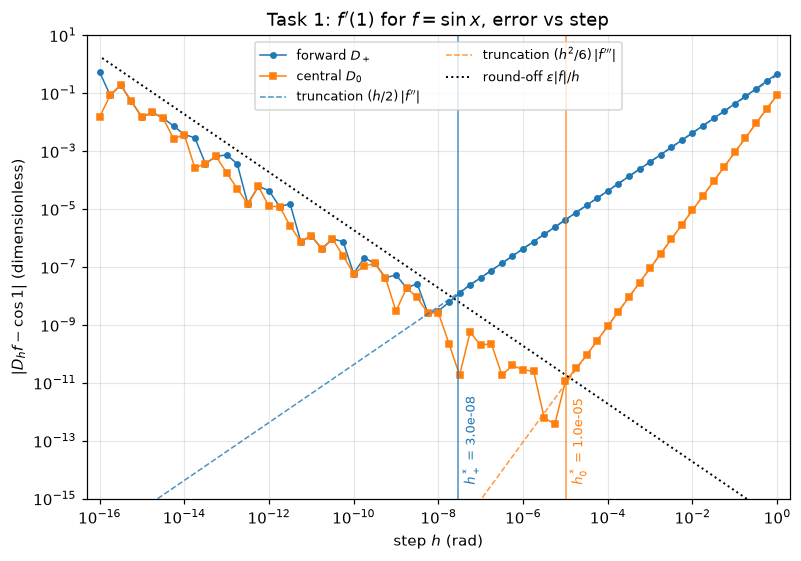

In [11]:
fig, ax = plt.subplots(figsize=(7.4, 5.2))
ax.loglog(H, abs(eP), 'o-', ms=3.5, lw=1, color='C0', label=r'forward $D_+$')
ax.loglog(H, abs(e0), 's-', ms=3.5, lw=1, color='C1', label=r'central $D_0$')
ax.loglog(H, H / 2 * f2, '--', lw=1, color='C0', alpha=0.8, label=r"truncation $(h/2)\,|f''|$")
ax.loglog(H, H**2 / 6 * f3, '--', lw=1, color='C1', alpha=0.8, label=r"truncation $(h^2/6)\,|f'''|$")
ax.loglog(H, EPS * f0 / H, 'k:', lw=1.3, label=r'round-off $\varepsilon|f|/h$')
for h_th, col, name in ((hP_th, 'C0', r'$h^*_+$'), (h0_th, 'C1', r'$h^*_0$')):
    ax.axvline(h_th, color=col, lw=1.0, alpha=0.8)
    ax.text(h_th * 1.25, 3e-15, f'{name} = {h_th:.1e}', color=col, fontsize=8.5, rotation=90, va='bottom')
ax.set_xlim(5e-17, 2)
ax.set_ylim(1e-15, 10)
ax.set_xlabel(r'step $h$ (rad)')
ax.set_ylabel(r'$|D_h f - \cos 1|$ (dimensionless)')
ax.set_title(r"Task 1: $f'(1)$ for $f = \sin x$, error vs step")
ax.legend(loc='upper center', fontsize=8.5, ncol=2)
fig.tight_layout()
fig.savefig(FIG / 'fig1_vshape.png')
plt.show()

**Reading the results:**

- **Truncation region (right arm).** The slope of D₊ is not exactly 1: the same fit applied to the exact truncation series itself gives the same value, so the extra 0.004 comes from the $h^2$ term $(h^2/6)f'''$, not from a bug. The next term of D₀ is $h^4$, so its slope is almost exactly 2. Every entry of table (a) matches the exact truncation error; only D₃ at h = 0.001 differs in the 3rd digit, because its error, 7×10⁻¹¹, is already close to the size of the round-off (bound 2ε|f|/h = 3.7×10⁻¹³).
- **Round-off region (left arm).** The slope is about −1, because the round-off error ∝ ε|f|/h. With the exact truncation error subtracted, every point with h ≤ 10⁻³ is inside the bound of the lecture notes: at most 24% (D₊) and 38% (D₀) of the bound, with medians of only 8% and 10%. The bound assumes that every rounding is the worst case and that they all add with the same sign; real roundings have random signs and are often less than one spacing. So **the measured minimum error is smaller than the theoretical e\***: 3.8×10⁻¹³ for D₀, against the theoretical bound 2.8×10⁻¹¹. What the theoretical h\* predicts is the **position** of the minimum (about 10⁻⁸ for D₊, about 10⁻⁵ for D₀), and that agrees.
- **h = 10⁻¹² is worse than h = 10⁻²**: 1.2×10⁻⁵ against 9.0×10⁻⁶. "Taking h a bit smaller to be safe" is wrong.
- **(d) Another grid.** The steps of the 2⁻ᵏ grid are exactly representable at x = 1, and the `temp` trick recovers the step actually used. Both give a minimum at the same position and of the same depth as the original grid, to within an order of magnitude. The reason is that for h ≥ 10⁻⁶ the actual step differs from the nominal h by less than 10⁻¹⁰ (relative), far below the round-off of sin itself. Only in the round-off region, h ≲ 10⁻¹², is the effect of the rounded step large enough to see.

## Task 2: the second derivative, Richardson extrapolation and the complex step (lecture notes §3.5–3.7)

Same h grid; $f''(1) = -\sin 1$. The theoretical optimal steps again come from `optimal_step`:

- D²: $(h^2/12)|f''''| + 4\varepsilon|f|/h^2$
- D₅: $(h^4/30)|f^{(5)}| + 1.5\varepsilon|f|/h$
- complex step: the exact error is $\cos 1\,(\sinh h/h - 1) = \cos 1\sum_{k\ge1}h^{2k}/(2k+1)!$, with no round-off term.

### (a) The second difference D²

In [12]:
f4, f5 = abs(np.sin(x0)), abs(np.cos(x0))              # |f''''(1)|, |f^(5)(1)|
e2 = second(np.sin, x0, H) + np.sin(x0)                # error against f''(1) = -sin 1
t2 = truncation_error(STENCILS['D2'], derivs, H)
s2, s2_ex = fit_slope(H[mt], e2[mt]), fit_slope(H[mt], t2[mt])
ok2 = H >= 1e-8 * (1 - 1e-9)                           # h < 1e-8: garbage, see below
i2 = np.flatnonzero(ok2)[np.argmin(abs(e2[ok2]))]
h2_th, e2_th = optimal_step(f4 / 12, 2, 4 * EPS * f0, 2)
print(f'D^2 truncation slope (h in [1e-3, 1e-1]): {s2:.4f}    same fit on the exact series {s2_ex:.4f}')
for h in (0.1, 0.01):
    i = nearest(H, h)
    print(f'  error at h = {h:<5}: {e2[i]:+.4e}    exact truncation {t2[i]:+.4e}')
print(f'best h = {H[i2]:.2e}, min |error| = {abs(e2[i2]):.2e};   theory h* = (48 eps|f|/|f4|)^(1/4) = {h2_th:.3e},'
      f' e* = {e2_th:.3e}')

D2_1e8 = second(np.sin, x0, 1e-8)
ulp = np.spacing(np.sin(x0))
print(f'\nD^2 at h = 1e-8 = {D2_1e8:.6f}   (exact {-np.sin(x0):.6f}: {abs(D2_1e8 / np.sin(x0) + 1):.0%} off)')
print(f'  numerator = {D2_1e8 * 1e-16:+.4e} = {D2_1e8 * 1e-16 / ulp:+.0f} x spacing of sin 1 ({ulp:.4e})')
print(f"  the true numerator h^2 f'' = {-np.sin(x0) * 1e-16:+.3e} is less than one spacing,"
      f' so D^2 can only come out as a multiple of {ulp / 1e-16:.4f}')

record('2a', 'D2 truncation slope', s2, s2_ex, 'fit to exact series', '2.000')
record('2a', 'D2 error, h = 0.1', e2[nearest(H, 0.1)], t2[nearest(H, 0.1)], 'exact trunc. series', '+7.010e-04')
record('2a', 'D2 error, h = 0.01', e2[nearest(H, 0.01)], t2[nearest(H, 0.01)], 'exact trunc. series', '+7.012e-06')
record('2a', 'D2 best h', H[i2], h2_th, 'theory h* (mag.)', '5.6e-05')
record('2a', 'D2 min |error|', abs(e2[i2]), e2_th, 'theory e* (bound)', '1.3e-09')
record('2a', 'D2 theory h*', h2_th, None, '', '3.21e-04')
record('2a', 'D2 theory e*', e2_th, None, '', '1.45e-08')
record('2a', 'D2 value at h = 1e-8', D2_1e8, -ulp / 1e-16, '-1 spacing / h^2', '-1.110')

D^2 truncation slope (h in [1e-3, 1e-1]): 2.0000    same fit on the exact series 2.0000
  error at h = 0.1  : +7.0099e-04    exact truncation +7.0099e-04
  error at h = 0.01 : +7.0122e-06    exact truncation +7.0122e-06
best h = 5.62e-05, min |error| = 1.28e-09;   theory h* = (48 eps|f|/|f4|)^(1/4) = 3.213e-04, e* = 1.448e-08

D^2 at h = 1e-8 = -1.110223   (exact -0.841471: 32% off)
  numerator = -1.1102e-16 = -1 x spacing of sin 1 (1.1102e-16)
  the true numerator h^2 f'' = -8.415e-17 is less than one spacing, so D^2 can only come out as a multiple of 1.1102


### (b) Richardson extrapolation $D_5 = [4D_0(h) - D_0(2h)]/3$

In [13]:
for h in (0.1, 0.01, 0.001):
    print(f'h = {h:<5}: Richardson D5 - five-point formula = {richardson5(np.sin, x0, h) - five_point(np.sin, x0, h):+.1e}')
e5 = richardson5(np.sin, x0, H) - d1
t5 = truncation_error(STENCILS['D5'], derivs, H)
m5 = in_range(H, 1e-2, 1e-1)
s5, s5_ex = fit_slope(H[m5], e5[m5]), fit_slope(H[m5], t5[m5])
i5 = np.argmin(abs(e5))
h5_th, e5_th = optimal_step(f5 / 30, 4, 1.5 * EPS * f0, 1)
print(f'\nD5 truncation slope (h in [1e-2, 1e-1], {m5.sum()} points): {s5:.4f}    same fit on the exact series {s5_ex:.4f}')
for h in (0.1, 0.01):
    i = nearest(H, h)
    print(f'  error at h = {h:<5}: {e5[i]:+.4e}    exact truncation {t5[i]:+.4e}')
print(f'best h = {H[i5]:.2e}, min |error| = {abs(e5[i5]):.2e};   theory h* = (11.25 eps|f|/|f5|)^(1/5) = {h5_th:.3e},'
      f' e* = {e5_th:.3e}')
print(f'min |error|: D0 {abs(e0[i0]):.1e}  ->  D5 {abs(e5[i5]):.1e}  (x{abs(e0[i0]) / abs(e5[i5]):.0f});'
      f'   theory e*: {e0_th:.1e} -> {e5_th:.1e}  (x{e0_th / e5_th:.0f})')

d5x = [abs(richardson5(np.sin, x0, h) - five_point(np.sin, x0, h)) for h in (0.1, 0.01, 0.001)]
record('2b', 'max |D5 - five-point|', max(d5x), 0.0, 'identical formulas', '< 1e-12')
record('2b', 'D5 truncation slope', s5, s5_ex, 'fit to exact series', '4.000')
record('2b', 'D5 error, h = 0.1', e5[nearest(H, 0.1)], t5[nearest(H, 0.1)], 'exact trunc. series', '-1.799e-06')
record('2b', 'D5 error, h = 0.01', e5[nearest(H, 0.01)], t5[nearest(H, 0.01)], 'exact trunc. series', '-1.801e-10')
record('2b', 'D5 best h', H[i5], h5_th, 'theory h* (mag.)', '5.6e-04')
record('2b', 'D5 min |error|', abs(e5[i5]), e5_th, 'theory e* (bound)', '1.8e-14')
record('2b', 'D5 theory h*', h5_th, None, '', '1.31e-03')
record('2b', 'D5 theory e*', e5_th, None, '', '2.67e-13')

h = 0.1  : Richardson D5 - five-point formula = -1.1e-16
h = 0.01 : Richardson D5 - five-point formula = -1.8e-15
h = 0.001: Richardson D5 - five-point formula = +3.7e-14

D5 truncation slope (h in [1e-2, 1e-1], 5 points): 3.9995    same fit on the exact series 3.9995
  error at h = 0.1  : -1.7989e-06    exact truncation -1.7989e-06
  error at h = 0.01 : -1.8010e-10    exact truncation -1.8010e-10
best h = 3.16e-04, min |error| = 1.54e-14;   theory h* = (11.25 eps|f|/|f5|)^(1/5) = 1.312e-03, e* = 2.670e-13
min |error|: D0 3.8e-13  ->  D5 1.5e-14  (x24);   theory e*: 2.8e-11 -> 2.7e-13  (x104)


### (c) The complex step $\mathrm{Im}\,\sin(1 + ih)/h$

In [14]:
Hc = np.concatenate([H, [1e-20, 1e-100]])
ec = complex_step(np.sin, x0, Hc) - d1
tc = complex_step_truncation_error(derivs, Hc)
mc = in_range(Hc, 1e-4, 1e-1)
sc = fit_slope(Hc[mc], ec[mc])
print(f'slope (h in [1e-4, 1e-1], {mc.sum()} points): {sc:.4f}')
print(f'error at h = 0.1: {ec[nearest(Hc, 0.1)]:+.4e}    exact cos1 (sinh h/h - 1) = {tc[nearest(Hc, 0.1)]:+.4e}')
tiny = Hc <= 1e-8 * (1 + 1e-9)
print(f'h <= 1e-8 ({tiny.sum()} values, including 1e-20 and 1e-100): errors = {sorted(set(ec[tiny].tolist()))}')
print(f'  exact truncation at h = 1e-8 is {tc[nearest(Hc, 1e-8)]:.1e}, below the spacing of cos 1 ({np.spacing(d1):.1e})')

record('2c', 'complex-step slope', sc, 2, 'theory order', '2.000')
record('2c', 'complex-step error, h = 0.1', ec[nearest(Hc, 0.1)], tc[nearest(Hc, 0.1)], 'cos1 (sinh h/h - 1)', '+9.010e-04')
record('2c', 'complex-step max |err|, h<=1e-8', abs(ec[tiny]).max(), 0.0, 'exact (no cancellation)', '0 or 1.1e-16')

slope (h in [1e-4, 1e-1], 13 points): 2.0000
error at h = 0.1: +9.0095e-04    exact cos1 (sinh h/h - 1) = +9.0095e-04
h <= 1e-8 (35 values, including 1e-20 and 1e-100): errors = [0.0]
  exact truncation at h = 1e-8 is 9.0e-18, below the spacing of cos 1 (1.1e-16)


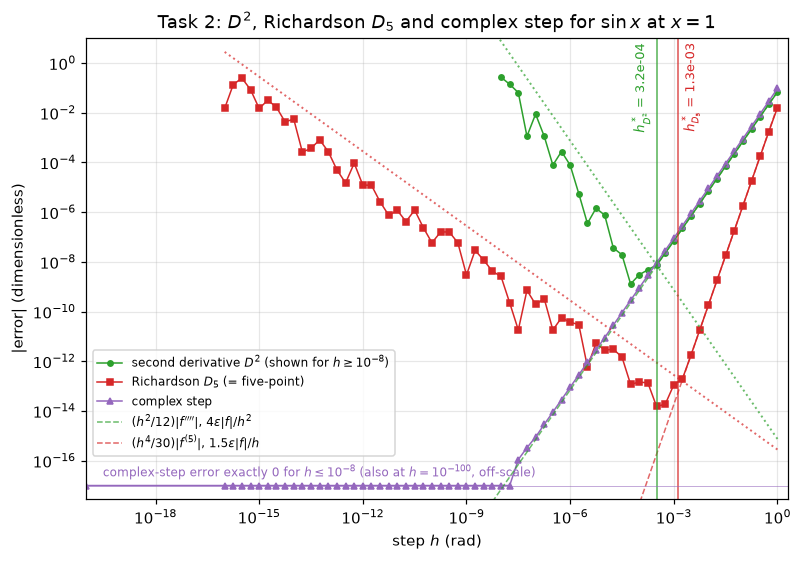

In [15]:
fig, ax = plt.subplots(figsize=(7.4, 5.2))
floor = 1e-17                                          # exactly-zero errors are drawn on this line
ax.loglog(H[ok2], abs(e2[ok2]), 'o-', ms=3.5, lw=1, color='C2', label=r"second derivative $D^2$ (shown for $h \geq 10^{-8}$)")
ax.loglog(H, abs(e5), 's-', ms=3.5, lw=1, color='C3', label=r'Richardson $D_5$ (= five-point)')
zero = ec == 0
show = Hc >= 1e-20
ax.loglog(Hc[show], np.where(zero, floor, abs(ec))[show], '^-', ms=4, lw=1, color='C4', label='complex step')
ax.loglog(H, H**2 / 12 * f4, '--', lw=1, color='C2', alpha=0.7, label=r"$(h^2/12)|f''''|$, $4\varepsilon|f|/h^2$")
ax.loglog(H[H > 1e-9], 4 * EPS * f0 / H[H > 1e-9]**2, ':', lw=1.3, color='C2', alpha=0.7)
ax.loglog(H, H**4 / 30 * f5, '--', lw=1, color='C3', alpha=0.7, label=r'$(h^4/30)|f^{(5)}|$, $1.5\varepsilon|f|/h$')
ax.loglog(H, 1.5 * EPS * f0 / H, ':', lw=1.3, color='C3', alpha=0.7)
for h_th, col in ((h2_th, 'C2'), (h5_th, 'C3')):
    ax.axvline(h_th, color=col, lw=1.0, alpha=0.8)
ax.axhline(floor, color='C4', lw=0.6, alpha=0.6)
ax.text(3e-20, floor * 2.2, r'complex-step error exactly 0 for $h \leq 10^{-8}$ (also at $h = 10^{-100}$, off-scale)',
        color='C4', fontsize=8)
ax.text(h2_th / 1.4, 3e-3, rf'$h^*_{{D^2}}$ = {h2_th:.1e}', color='C2', fontsize=8.5, rotation=90, ha='right')
ax.text(h5_th * 1.3, 3e-3, rf'$h^*_{{D_5}}$ = {h5_th:.1e}', color='C3', fontsize=8.5, rotation=90, ha='left')
ax.set_xlim(1e-20, 2)
ax.set_ylim(3e-18, 10)
ax.set_xlabel(r'step $h$ (rad)')
ax.set_ylabel(r'|error| (dimensionless)')
ax.set_title(r'Task 2: $D^2$, Richardson $D_5$ and complex step for $\sin x$ at $x = 1$')
ax.legend(loc='lower left', bbox_to_anchor=(0.0, 0.08), fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'fig2_higher.png')
plt.show()

**Reading the results:**

- **The minimum of D² lies to the right of D₀'s and is shallower.** The round-off term of D² is 4ε|f|/h², which grows faster than 1/h as h shrinks, so the balance point moves to larger h: h\* ∝ ε^{1/4} ≈ 3×10⁻⁴, against ε^{1/3} ≈ 10⁻⁵ for D₀. The height of the minimum ∝ ε^{1/2} ≈ 10⁻⁸, leaving only about 8 significant digits (the general rule of lecture notes §3.5: h\* ∝ ε^{1/(p+k)}, e\* ∝ ε^{p/(p+k)}).
- **D² = −1.1102 at h = 10⁻⁸ is not just any wrong number.** The true value of the numerator sin(1+h) − 2 sin 1 + sin(1−h) is h²f'' = −8.4×10⁻¹⁷, smaller than one spacing near sin 1, 1.11×10⁻¹⁶. The computed numerator can only be an integer multiple of the spacing, here −1 times; divided by h² that gives −1.1102. For smaller h the answer can only be an integer multiple of 1.1102×(10⁻⁸/h)² (including 0), so the plot shows no points with h < 10⁻⁸.
- **The smallest error of D₅ is about two orders of magnitude better than D₀'s.** The truncation error ∝ h⁴, so a much larger h (about 10⁻³) can be used, which makes the round-off term 1.5ε|f|/h much smaller. The accuracy improves from ε^{2/3} to ε^{4/5}, a factor of 100 between the bounds. The measured minimum, 1.5×10⁻¹⁴, is 24 times better than D₀'s 3.8×10⁻¹³; both are luckier than their bounds, so the factor agrees only in order of magnitude. The difference between D₅ and the five-point formula, 10⁻¹⁶–10⁻¹⁴, is only round-off from a different order of operations.
- **The complex step has no left arm.** Taking the imaginary part subtracts no two nearly equal numbers, so the round-off is not amplified by 1/h. For h ≤ 10⁻⁸ the truncation error (about 10⁻¹⁷) is already below half a spacing of cos 1, and the result is **exactly** `np.cos(1.0)`: the error is 0, even at h = 10⁻¹⁰⁰. The right arm has the same truncation error as D₀ (both have the leading term h²|f'''|/6), with the opposite sign.

## Task 3: without an analytic derivative: $C_V = dU/dT$ of Cu (lecture notes §3.4, §3.6)

$$U(T) = 9RT\left(\frac{T}{\theta_D}\right)^3\int_0^{\theta_D/T}\frac{x^3}{e^x-1}\,dx,\qquad \theta_D = 343\ \mathrm{K},\quad R = 8.314462618\ \mathrm{J\,mol^{-1}\,K^{-1}}$$

**Numerical pitfalls and how they are handled (`energy_integrand` in `debye_energy.py`):** the integrand is rewritten as $x^3e^{-x}/(1-e^{-x})$, with the denominator computed as `-expm1(-x)`.

1. $x \to 0$ is $0/0$, and the first grid point is $x = 0$. For $x < 10^{-8}$ the series $x^2(1 - x/2)$ is used instead. The next term here is $-x/2$, much larger than the $-x^2/12$ of week 1's C_V integrand, so this term has to be kept for the dropped $x^2/12$ to be smaller than the round-off.
2. At low temperature the upper limit is large: the rewritten form contains only $e^{-x}$, which underflows harmlessly to 0 instead of overflowing.

**An independent check (without quadrature).** Integrating $1/(e^x-1) = \sum_k e^{-kx}$ term by term,

$$J(u) = \int_0^u\frac{x^3}{e^x-1}dx = \frac{\pi^4}{15} - \sum_{k\ge1}e^{-ku}\left(\frac{u^3}{k}+\frac{3u^2}{k^2}+\frac{6u}{k^3}+\frac{6}{k^4}\right),\qquad u = \theta_D/T .$$

At T = 100 K, u = 3.43, so each extra term is smaller by $e^{-3.43} \approx 1/31$, and 60 terms reach machine precision. Differentiating with respect to T, the upper limit also moves with T (Leibniz rule), which gives

$$C_V = \frac{dU}{dT} = \frac{4U}{T} - \frac{9Ru}{e^u - 1},\qquad \frac{dC_V}{dT} = \frac{3C_V}{T} - \frac{9R}{\theta_D}\,\frac{u^3e^u}{(e^u-1)^2}.$$

- The first formula is week 1's C_V integral after integration by parts, so the referee value gets one more independent check.
- The second formula consists only of operations that accept complex numbers, so one more differentiation by the **complex step** of Task 2 gives $U''' = d^2C_V/dT^2$ to machine precision. Differentiating that with D² gives the higher derivatives $U^{(5)}$ and $U^{(7)}$, which predict the next terms of the finite-difference error.

In [16]:
x_demo = np.array([0.0, 1e-9, 1e-3, 1.0, 50.0, 709.0, 710.0, 1000.0])
with np.errstate(all='ignore'):
    naive = x_demo**3 / (np.exp(x_demo) - 1)
print('        x      textbook x^3/(e^x-1)     safe form')
for x, a, s_ in zip(x_demo, naive, energy_integrand(x_demo)):
    print(f'{x:9.3g}     {a:14.6e}        {s_:14.6e}')

T0 = 100.0
U100 = debye_energy(T0)                                # Simpson, N = 2048
U100_ser = debye_energy_series(T0)
judge = debye_cv(T0, N=4096)                           # week 1 formula, Simpson N = 4096: the referee
cv_ser = debye_cv_series(T0)
print(f'\nU(100 K), Simpson N = 2048        = {U100:.10f} J/mol')
print(f'U(100 K), series                  = {U100_ser:.10f} J/mol      rel. diff {abs(U100 / U100_ser - 1):.1e}')
print(f'referee C_V(100 K), week 1 N=4096 = {judge:.12f} J/(mol K)')
print(f'C_V = 4U/T - 9Ru/(e^u-1), series  = {cv_ser:.12f} J/(mol K)   rel. diff {abs(judge / cv_ser - 1):.1e}')

record('3', 'U(100 K) (J/mol)', U100, U100_ser, 'series, no quadrature', '583.92606')
record('3', 'referee C_V(100 K)', judge, cv_ser, 'series 4U/T - 9Ru/(e^u-1)', '14.7661353904')

        x      textbook x^3/(e^x-1)     safe form
        0                nan          0.000000e+00
    1e-09       9.999999e-19          1.000000e-18
    0.001       9.995001e-07          9.995001e-07
        1       5.819767e-01          5.819767e-01
       50       2.410937e-17          2.410937e-17
      709      4.336617e-300         4.336617e-300
      710       0.000000e+00         1.602112e-300
    1e+03       0.000000e+00          0.000000e+00

U(100 K), Simpson N = 2048        = 583.9260611687 J/mol
U(100 K), series                  = 583.9260611687 J/mol      rel. diff 4.6e-14
referee C_V(100 K), week 1 N=4096 = 14.766135390417 J/(mol K)
C_V = 4U/T - 9Ru/(e^u-1), series  = 14.766135390417 J/(mol K)   rel. diff 8.9e-16


### Step 2: three steps and Richardson extrapolation

h = 4, 2, 1 K are successive halvings, so week 1's `observed_order_3grid` and `richardson` can be used directly. The error expansion of D₀ has only even powers, so Richardson extrapolation uses the theoretical p = 2 (p_obs serves to confirm this); the result with p_obs is listed as well.

In [17]:
Q1, Q2, Q3 = (central(debye_energy, T0, h) for h in (4.0, 2.0, 1.0))
d12, d23 = Q1 - Q2, Q2 - Q3
p_obs = observed_order_3grid(Q1, Q2, Q3)
Qstar = richardson(Q2, Q3, p=2)                        # = (4 Q3 - Q2)/3 = D5 with h = 1 K
Qstar_pobs = richardson(Q2, Q3, p=p_obs)
est = abs(Qstar - Q3)

# Exact higher derivatives of U at 100 K (series + complex step), to predict the errors
U3 = lambda T: complex_step(debye_dcv_series, T, 1e-20)     # U''' = d^2 C_V/dT^2 to round-off
U3x = U3(T0)
U5x = second(U3, T0, 0.25)                                   # U^(5); D^2 truncation ~1e-4 relative
U7x = U3(T0 + 2) - 4 * U3(T0 + 1) + 6 * U3(T0) - 4 * U3(T0 - 1) + U3(T0 - 2)   # U^(7), 4th difference, h = 1 K
pred_Q3 = U3x / 6 + U5x / 120 + U7x / 5040                   # D0 error series at h = 1 K
pred_D5 = -U5x / 30 - U7x / 252                              # D5 error series at h = 1 K

print(f'Q1, Q2, Q3 (h = 4, 2, 1 K) = {Q1:.6f}  {Q2:.6f}  {Q3:.6f}  J/(mol K)')
print(f'Q1 - Q2 = {d12:.4e},  Q2 - Q3 = {d23:.4e},  ratio = {d12 / d23:.4f}   (2^2 = 4)')
print(f'p_obs = {p_obs:.4f}')
print(f'Richardson Q* (p = 2)     = {Qstar:.10f}')
print(f'Richardson Q* (p = p_obs) = {Qstar_pobs:.10f}')
print(f'error estimate of h = 1 K: |Q* - Q3| = {est:.4e}')
print(f'\nagainst the referee {judge:.10f}:')
print(f'  Q3 - referee           = {Q3 - judge:+.5e}   predicted (h^2/6)U3 + (h^4/120)U5 + (h^6/5040)U7 = {pred_Q3:+.5e}')
print(f'  Q* - referee (p = 2)   = {Qstar - judge:+.4e}   predicted -(h^4/30)U5 - (h^6/252)U7 = {pred_D5:+.4e}')
print(f'  Q* - referee (p_obs)   = {Qstar_pobs - judge:+.4e}')
print(f'  |Q3 error| / |Q* error|: p = 2 -> {abs(Q3 - judge) / abs(Qstar - judge):.0f},  p_obs -> {abs(Q3 - judge) / abs(Qstar_pobs - judge):.0f}')
print(f"\n(U''' = {U3x:.6e} J mol^-1 K^-3,  U^(5) = {U5x:.4e} J mol^-1 K^-5,  U^(7) = {U7x:.3e} J mol^-1 K^-7)")

record('3', 'Q1 (h = 4 K)', Q1, judge + U3x * 16 / 6 + U5x * 256 / 120 + U7x * 4096 / 5040, 'referee + error series', '14.760043')
record('3', 'Q2 (h = 2 K)', Q2, judge + U3x * 4 / 6 + U5x * 16 / 120 + U7x * 64 / 5040, 'referee + error series', '14.764612')
record('3', 'Q3 (h = 1 K)', Q3, judge + pred_Q3, 'referee + error series', '14.765755')
record('3', 'ratio (Q1-Q2)/(Q2-Q3)', d12 / d23, 4, 'theory 2^p', '3.9993')
record('3', 'p_obs', p_obs, 2, 'theory order', '1.9997')
record('3', 'Q* (p = 2)', Qstar, cv_ser, 'series C_V', '14.7661355')
record('3', 'Q* (p = p_obs)', Qstar_pobs, cv_ser, 'series C_V', '14.7661355')
record('3', 'error estimate |Q* - Q3|', est, abs(Q3 - judge), 'actual |Q3 - referee|', '3.81e-04')
record('3', 'Q3 - referee', Q3 - judge, pred_Q3, 'error series', '-3.81e-04')
record('3', 'Q* (p=2) - referee', Qstar - judge, pred_D5, '-(h^4/30)U5 - ...', '7e-08 (p_obs)')

Q1, Q2, Q3 (h = 4, 2, 1 K) = 14.760043  14.764612  14.765755  J/(mol K)
Q1 - Q2 = -4.5688e-03,  Q2 - Q3 = -1.1424e-03,  ratio = 3.9993   (2^2 = 4)
p_obs = 1.9997
Richardson Q* (p = 2)     = 14.7661353720
Richardson Q* (p = p_obs) = 14.7661354644
error estimate of h = 1 K: |Q* - Q3| = 3.8080e-04

against the referee 14.7661353904:
  Q3 - referee           = -3.80823e-04   predicted (h^2/6)U3 + (h^4/120)U5 + (h^6/5040)U7 = -3.80823e-04
  Q* - referee (p = 2)   = -1.8376e-08   predicted -(h^4/30)U5 - (h^6/252)U7 = -1.8377e-08
  Q* - referee (p_obs)   = +7.4004e-08
  |Q3 error| / |Q* error|: p = 2 -> 20724,  p_obs -> 5146

(U''' = -2.284966e-03 J mol^-1 K^-3,  U^(5) = 5.5041e-07 J mol^-1 K^-5,  U^(7) = 7.546e-09 J mol^-1 K^-7)


### Steps 3–4: h from 10 K to 10⁻¹² K; the theoretical optimal step

In [18]:
H3 = 10.0 ** (1 - np.arange(27) / 2)                   # 10 K ... 1e-12 K, 2 points per decade
e3 = np.array([central(debye_energy, T0, h) for h in H3]) - judge
i3 = np.argmin(abs(e3))
print('      h (K)     D0 - referee    (h^2/6)U3     eps|U|/h')
for h, e in zip(H3, e3):
    print(f'  {h:9.2e}   {e:+12.4e}   {h**2 / 6 * U3x:+11.3e}   {EPS * U100 / h:9.2e}')

U3_fd = second(debye_cv, T0, 1.0)                      # step 4: D^2 of week 1's C_V(T), h = 1 K
xc = (abs(U100) / abs(U3_fd)) ** (1 / 3)
xc_sin = (np.sin(1.0) / np.cos(1.0)) ** (1 / 3)
h3_th, e3_th = optimal_step(abs(U3_fd) / 6, 2, EPS * abs(U100), 1)
print(f"\nU''' = d^2C_V/dT^2 by D^2 (h = 1 K) = {U3_fd:.5e} J mol^-1 K^-3;  exact (complex step) {U3x:.5e};"
      f'  rel. diff {abs(U3_fd / U3x - 1):.1e}')
print(f"characteristic scale x_c = (|U|/|U'''|)^(1/3) = {xc:.2f} K      (sin x at x = 1: {xc_sin:.3f})")
print(f"theory h* = (3 eps|U|/|U'''|)^(1/3) = {h3_th:.3e} K = (3 eps)^(1/3) x_c;   theory e* = {e3_th:.2e}")
print(f'measured: best h = {H3[i3]:.2e} K, min |error| = {abs(e3[i3]):.2e} J/(mol K)')
print(f'V shift relative to Task 1: h*_Debye / h*_sin = {h3_th / h0_th:.1f} = x_c ratio {xc / xc_sin:.1f}')
q = central(debye_energy, T0, 1e-12)
print(f'\nh = 1e-12 K: U(T+h) - U(T-h) = {(q * 2e-12) / np.spacing(U100):.0f} spacings of U (spacing {np.spacing(U100):.2e});'
      f' D0 moves in steps of {np.spacing(U100) / 2e-12:.3f} J/(mol K)')

for h in (1.0, 0.1, 0.01):
    record('3', f'D0 - referee, h = {h:g} K', e3[nearest(H3, h)], h**2 / 6 * U3x + h**4 / 120 * U5x,
           'error series', f'{-3.81e-4 * h**2:.2e}')
record('3', "U''' by D^2 (h = 1 K)", U3_fd, U3x, 'complex step, series', '-2.285e-03')
record('3', 'x_c (K)', xc, (abs(U100_ser) / abs(U3x)) ** (1 / 3), 'exact derivatives', '63.5')
record('3', 'theory h* (K)', h3_th, None, '', '5.5e-04')
record('3', 'best h on grid (K)', H3[i3], h3_th, 'theory h* (mag.)', '3e-04')
record('3', 'min |D0 - referee|', abs(e3[i3]), e3_th, 'theory e* (bound)', '4e-11')

      h (K)     D0 - referee    (h^2/6)U3     eps|U|/h
   1.00e+01    -3.8035e-02    -3.808e-02    1.30e-14
   3.16e+00    -3.8078e-03    -3.808e-03    4.10e-14
   1.00e+00    -3.8082e-04    -3.808e-04    1.30e-13
   3.16e-01    -3.8083e-05    -3.808e-05    4.10e-13
   1.00e-01    -3.8083e-06    -3.808e-06    1.30e-12
   3.16e-02    -3.8083e-07    -3.808e-07    4.10e-12
   1.00e-02    -3.8083e-08    -3.808e-08    1.30e-11
   3.16e-03    -3.7817e-09    -3.808e-09    4.10e-11
   1.00e-03    -2.9878e-10    -3.808e-10    1.30e-10
   3.16e-04    -4.2755e-11    -3.808e-11    4.10e-10
   1.00e-04    +2.6965e-10    -3.808e-12    1.30e-09
   3.16e-05    +2.1143e-09    -3.808e-13    4.10e-09
   1.00e-05    +8.7962e-09    -3.808e-14    1.30e-08
   3.16e-06    +4.3458e-08    -3.808e-15    4.10e-08
   1.00e-06    -1.6742e-07    -3.808e-16    1.30e-07
   3.16e-07    -6.4395e-08    -3.808e-17    4.10e-07
   1.00e-07    -6.2217e-07    -3.808e-18    1.30e-06
   3.16e-08    -7.8341e-07    -3.808e-19    

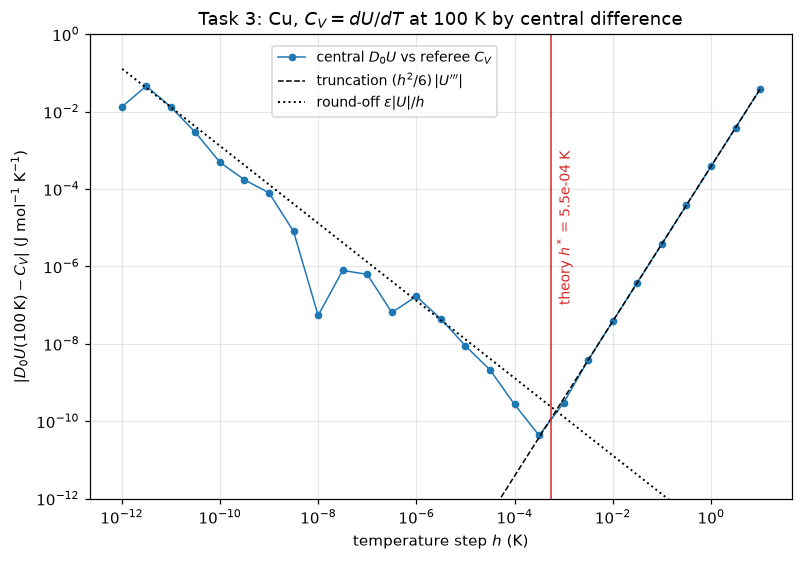

In [19]:
fig, ax = plt.subplots(figsize=(7.4, 5.2))
ax.loglog(H3, abs(e3), 'o-', ms=4, lw=1, color='C0', label=r'central $D_0 U$ vs referee $C_V$')
ax.loglog(H3, H3**2 / 6 * abs(U3x), 'k--', lw=1, label=r"truncation $(h^2/6)\,|U'''|$")
ax.loglog(H3, EPS * U100 / H3, 'k:', lw=1.3, label=r'round-off $\varepsilon|U|/h$')
ax.axvline(h3_th, color='C3', lw=1.0)
ax.text(h3_th * 1.3, 1e-7, rf'theory $h^*$ = {h3_th:.1e} K', color='C3', fontsize=9, rotation=90, va='bottom')
ax.set_ylim(1e-12, 1)
ax.set_xlabel(r'temperature step $h$ (K)')
ax.set_ylabel(r'$|D_0U(100\,\mathrm{K}) - C_V|$ (J mol$^{-1}$ K$^{-1}$)')
ax.set_title(r'Task 3: Cu, $C_V = dU/dT$ at 100 K by central difference')
ax.legend(loc='upper center', bbox_to_anchor=(0.42, 0.99), fontsize=9)
fig.tight_layout()
fig.savefig(FIG / 'fig3_debye_dUdT.png')
plt.show()

**Reading the results:**

- **p_obs = 1.9997 ≈ 2**: all three steps are in the asymptotic region dominated by truncation, where the error has the form $Ch^2$, so the premise of Richardson extrapolation holds. The difference of 2.6×10⁻⁴ between p_obs and 2 comes from the $h^4$ term $(h^4/120)U^{(5)}$.
- **The error estimate is very accurate.** $|Q^* - Q_3| = 3.8080\times10^{-4}$, while the true error of Q₃ is 3.8082×10⁻⁴, only 0.005% different. The error of Q₃ itself also matches the prediction of the error series to 9 digits.
- **The error of Q\*.** With p = 2, Q\* differs from the referee value by only −1.84×10⁻⁸, about 20,000 times smaller than Q₃. This Q\* is the five-point formula D₅ at h = 1 K, and its error $-(h^4/30)U^{(5)} - (h^6/252)U^{(7)}$ is also predicted accurately. Using p_obs instead extrapolates the bias caused by the h⁴ term as if it were part of h², and the result is 4 times worse (7.4×10⁻⁸).
- **The optimal step is 10⁻⁴–10⁻³ K, not the 10⁻⁵ of Task 1.** The theoretical h\* = (3ε)^{1/3} x_c, where $x_c = (|U|/|U'''|)^{1/3} = 63.5$ K is the characteristic scale of U(T). For sin x at x = 1, x_c = 1.16; the ratio is 55, so the whole V moves 55 times to the right. The measured minimum, 3.2×10⁻⁴ K, is within an order of magnitude of the theoretical h\* = 5.5×10⁻⁴ K. "Take 10⁻⁵ for central differences" holds only when the variable is already of order 1.
- **The numbers on the left arm come in steps.** At h = 10⁻¹² K, U(T+h) − U(T−h) is only 260 "spacings of U" (1.1×10⁻¹³ J/mol), so D₀ can only jump in units of 0.057 J mol⁻¹ K⁻¹. The error of the left arm is this quantization.

## Task 4: the bulk modulus of Cu: verification, noise and validation (lecture notes §3.8–3.9)

Morse pair potential (Girifalco & Weizer 1959): $\phi(r) = D[e^{-2\alpha(r-r_0)} - 2e^{-\alpha(r-r_0)}]$, $D = 0.3429$ eV, $\alpha = 1.3588$ Å⁻¹, $r_0 = 2.866$ Å.

- Energy per atom $E(a) = \tfrac12\sum_j\phi(a|s_j|)$, where $s_j$ are the FCC lattice points in units of the lattice constant a, with $0 < |s_j| \le 5.5$. **The neighbour list is built once and not re-selected when a changes**, so E(a) is a smooth function of a.
- Derivatives: $E^{(n)}(a) = \tfrac12\sum_j|s_j|^n\phi^{(n)}(a|s_j|)$, with $\phi^{(n)}(r) = D[(-2\alpha)^n e^{-2\alpha(r-r_0)} - 2(-\alpha)^n e^{-\alpha(r-r_0)}]$.
- Bulk modulus $B = 4E''(a_0)/(9a_0)$, 1 eV/Å³ = 160.21766 GPa.

**The exact truncation error of D².** E(a) is a sum of exponentials $e^{-ca}$ ($c = 2\alpha|s_j|$ or $\alpha|s_j|$), and $D^2 e^{-ca} = e^{-ca}\cdot 2(\cosh ch - 1)/h^2$ (exactly). Therefore

$$D^2E - E'' = \frac{1}{2h^2}\sum_j D\left[e^{-2\alpha(a|s_j| - r_0)}\,g(2\alpha |s_j| h) - 2e^{-\alpha(a|s_j| - r_0)}\,g(\alpha |s_j| h)\right],\qquad g(y) = 2(\cosh y - 1) - y^2 = \frac{y^4}{12} + \frac{y^6}{360} + \cdots$$

For small y, g is summed as a series, and the whole expression avoids subtracting "$D^2E - E''$", so it stays accurate however small h is (`morse.second_difference_error`).

### (a) Equilibrium

In [20]:
s = fcc_neighbours(5.5)
radii, counts = fcc_shells(s)
a0 = equilibrium(s)
E0, E1, E2, E4 = (energy(a0, s, n) for n in (0, 1, 2, 4))
B = bulk_modulus(E2, a0)
# Independent check of the analytic derivatives: complex step on the derivative one order lower
E2_cs = complex_step(lambda a: energy(a, s, 1), a0, 1e-20)
E4_cs = complex_step(lambda a: energy(a, s, 3), a0, 1e-20)
print(f'neighbours with 0 < |s| <= 5.5 : {len(s)}   ({len(radii)} shells; farthest |s| = {s.max():.4f} -> {s.max() * a0:.2f} Å)')
print(f'first shells: |s|^2 = {[float(r) for r in radii[:8]**2]}')
print(f'               sites = {counts[:8].tolist()}')
print(f"a0          = {a0:.9f} Å        (E'(a0) = {E1:+.1e} eV/Å)")
print(f'E(a0)       = {E0:.9f} eV/atom')
print(f"E''(a0)     = {E2:.8f} eV/Å^2     complex step of E'  : {E2_cs:.8f}  (rel. diff {abs(E2 / E2_cs - 1):.0e})")
print(f"E''''(a0)   = {E4:.6f} eV/Å^4     complex step of E''': {E4_cs:.6f}  (rel. diff {abs(E4 / E4_cs - 1):.0e})")
print(f'B analytic  = 4E\'\'/(9 a0) = {B:.4f} GPa')

print('\nlattice-sum cutoff, all at the same a0:')
print('  s_max   sites      E(a0) (eV/atom)      E - E(5.5) (eV)      B (GPa)')
cut = {}
for smax in (5.5, 6.0, 6.5, 7.0, 8.0, 10.0):
    ss = fcc_neighbours(smax)
    cut[smax] = (energy(a0, ss), bulk_modulus(energy(a0, ss, 2), a0))
    print(f'  {smax:5.1f}   {len(ss):5d}   {cut[smax][0]:.15f}    {cut[smax][0] - E0:+.4e}       {cut[smax][1]:.8f}')
dE7 = cut[7.0][0] - E0
tail = 0.5 * 4 * quad(lambda t: 4 * np.pi * t**2 * phi(a0 * t), 5.5, 60, limit=200)[0]   # 4 sites per a^3
r7, n7 = fcc_shells(fcc_neighbours(7.0))
first_out = np.flatnonzero(r7 > 5.5)[0]
print(f'\n|s| <= 7 changes E(a0) by {dE7:+.3e} eV  -> |change| {"<" if abs(dE7) < 1e-8 else ">"} 1e-8 eV')
print(f'continuum estimate of the whole tail beyond |s| = 5.5: (1/2)(4/a^3) int 4 pi r^2 phi dr = {tail:+.3e} eV')
print(f'first shell beyond 5.5 alone (|s|^2 = {r7[first_out]**2:.1f}, {n7[first_out]} sites): '
      f'{0.5 * n7[first_out] * phi(a0 * r7[first_out]):+.2e} eV')
print(f'effect of the 5.5 cutoff on B: {cut[10.0][1] - B:+.1e} GPa ({abs(cut[10.0][1] / B - 1):.0e} relative)')

record('4a', 'neighbours (0 < |s| <= 5.5)', len(s), None, '', '2778')
record('4a', 'a0 (Å)', a0, None, '', '3.606407')
record('4a', "E'(a0) (eV/Å)", E1, 0.0, 'equilibrium', '')
record('4a', 'E(a0) (eV/atom)', E0, None, '', '-3.542855')
record('4a', "E''(a0) (eV/Å^2)", E2, E2_cs, "complex step of E'", '7.07158')
record('4a', "E''''(a0) (eV/Å^4)", E4, E4_cs, "complex step of E'''", '52.358')
record('4a', 'B analytic (GPa)', B, None, '', '139.627')
record('4a', 'E(a0): |s|<=7 minus |s|<=5.5', dE7, tail, 'continuum tail estimate', '~1.4e-09')

neighbours with 0 < |s| <= 5.5 : 2778   (56 shells; farthest |s| = 5.4772 -> 19.75 Å)
first shells: |s|^2 = [0.5000000000000001, 1.0, 1.4999999999999998, 2.0000000000000004, 2.5000000000000004, 2.9999999999999996, 3.5, 4.0]
               sites = [12, 6, 24, 12, 24, 8, 48, 6]
a0          = 3.606407346 Å        (E'(a0) = +2.7e-14 eV/Å)
E(a0)       = -3.542854569 eV/atom
E''(a0)     = 7.07157776 eV/Å^2     complex step of E'  : 7.07157776  (rel. diff 0e+00)
E''''(a0)   = 52.357603 eV/Å^4     complex step of E''': 52.357603  (rel. diff 0e+00)
B analytic  = 4E''/(9 a0) = 139.6270 GPa

lattice-sum cutoff, all at the same a0:
  s_max   sites      E(a0) (eV/atom)      E - E(5.5) (eV)      B (GPa)
    5.5    2778   -3.542854568682560    +0.0000e+00       139.62700064
    6.0    3588   -3.542854578915017    -1.0232e-08       139.62698872
    6.5    4584   -3.542854580014954    -1.1332e-08       139.62698721
    7.0    5774   -3.542854580124272    -1.1442e-08       139.62698703
    8.0    8588  

### (b) Verification (no noise): B from E(a) by D²

In [21]:
E = lambda a: energy(a, s)
Hb = 10.0 ** (-np.arange(37) / 4)                      # 1 ... 1e-9 Å, 4 points per decade
B_fd = bulk_modulus(second(E, a0, Hb), a0)
rel_b = (B_fd - B) / B
trunc_b = np.array([bulk_modulus(second_difference_error(a0, h, s), a0) for h in Hb])   # exact, GPa
mb = in_range(Hb, 1e-3, 1e-1)
sb = fit_slope(Hb[mb], rel_b[mb])
sb_ex = fit_slope(Hb[mb], trunc_b[mb])
coef_th = 4 / (9 * a0) * E4 / 12 * EV_PER_A3_IN_GPA
print(f'truncation slope (h in [1e-3, 1e-1]): {sb:.4f}     same fit on the exact truncation error {sb_ex:.4f}')
print(f'\n  h (Å)      B_FD (GPa)      (B_FD - B)/h^2     exact truncation/h^2    theory (4/9a0)(E4/12)(160.2)')
for h in (0.1, 0.01, 0.001):
    i = nearest(Hb, h)
    print(f'  {h:<6}   {B_fd[i]:13.7f}     {(B_fd[i] - B) / h**2:12.5f}       {trunc_b[i] / h**2:12.5f}           {coef_th:.5f}')
ib = np.argmin(abs(rel_b))
hb_th, eb_th = optimal_step(E4 / 12, 2, 4 * EPS * abs(E0), 2)
print(f'\nbest h = {Hb[ib]:.2e} Å, relative error {abs(rel_b[ib]):.1e};   theory h* = (48 eps|E|/|E4|)^(1/4) = {hb_th:.2e} Å,'
      f' e*/B = {bulk_modulus(eb_th, a0) / B:.1e}')
print('round-off part (B_FD - B - exact truncation)/B:',
      ', '.join(f'h={Hb[i]:.0e}: {(B_fd[i] - B - trunc_b[i]) / B:+.1e}' for i in (nearest(Hb, 1e-2), nearest(Hb, 1e-4), nearest(Hb, 1e-6))))

record('4b', 'truncation slope', sb, sb_ex, 'fit to exact trunc.', '2.000')
for h, ref in ((0.1, '140.490'), (0.01, '139.6356')):
    i = nearest(Hb, h)
    record('4b', f'B_FD, h = {h} Å', B_fd[i], B + trunc_b[i], 'B + exact truncation', ref)
for h, ref in ((0.1, '86.31'), (0.01, '86.15'), (0.001, '86.2')):
    i = nearest(Hb, h)
    record('4b', f'(B_FD - B)/h^2, h = {h}', (B_fd[i] - B) / h**2, trunc_b[i] / h**2, 'exact truncation/h^2', ref)
record('4b', 'theory coefficient (GPa/Å^2)', coef_th, None, '', '86.15')
record('4b', 'best h, no noise (Å)', Hb[ib], hb_th, 'theory h* (mag.)', '~2e-04')
record('4b', 'min relative error of B', abs(rel_b[ib]), None, '', '~3e-08')

truncation slope (h in [1e-3, 1e-1]): 2.0002     same fit on the exact truncation error 2.0003

  h (Å)      B_FD (GPa)      (B_FD - B)/h^2     exact truncation/h^2    theory (4/9a0)(E4/12)(160.2)
  0.1        140.4900520         86.30514           86.30514           86.14927
  0.01       139.6356157         86.15083           86.15083           86.14927
  0.001      139.6270869         86.21281           86.14929           86.14927

best h = 1.00e-04 Å, relative error 3.2e-08;   theory h* = (48 eps|E|/|E4|)^(1/4) = 1.64e-04 Å, e*/B = 3.3e-08
round-off part (B_FD - B - exact truncation)/B: h=1e-02: +2.5e-12, h=1e-04: +2.6e-08, h=1e-06: +5.8e-04


### (c) Noise: $\delta\times U(-1, 1)$ added to every call of E(a)

h = 10⁰ to 10⁻⁵ Å (8 points per decade), 200 repetitions per h; the rms error of B is taken.

**Predicting the rms (without simulation).** The noise part of $D^2$ is $(\delta_1 - 2\delta_2 + \delta_3)/h^2$, where the $\delta_i$ are independent and uniform on $[-\delta, \delta]$, each with variance $\delta^2/3$, so its variance is $(1 + 4 + 1)\delta^2/3h^4 = 2\delta^2/h^4$. The expected mean-square error is then (exact truncation error)² + $2\delta^2/h^4$. With the leading term only, its minimum is at

$$h^*_{\rm rms} = \left(\frac{12\sqrt2\,\delta}{|E''''|}\right)^{1/4},$$

a factor $(\sqrt2/4)^{1/4} = 0.77$ smaller than $h^* = (48\delta/|E''''|)^{1/4}$ from the bound model used in the lecture notes (four δ of the same sign, $4\delta/h^2$).

In [22]:
rng = np.random.default_rng(SEED)
Hn = 10.0 ** (-np.arange(41) / 8)                      # 1 ... 1e-5 Å, 8 points per decade
A0 = np.full(200, a0)                                  # 200 repetitions per h, vectorised; each call draws new noise


def rms_B_error(delta):
    En = noisy(E, delta, rng)
    return np.array([np.sqrt(np.mean((bulk_modulus(second(En, A0, h), a0) - B) ** 2)) for h in Hn])


def rms_B_predicted(delta):
    bias = np.array([second_difference_error(a0, h, s) for h in Hn])
    return bulk_modulus(np.sqrt(bias**2 + 2 * delta**2 / Hn**4), a0)


res = {}
for delta in (1e-5, 1e-4):
    rms, pred = rms_B_error(delta), rms_B_predicted(delta)
    j, jp = np.argmin(rms), np.argmin(pred)
    h_bound, _ = optimal_step(E4 / 12, 2, 4 * delta, 2)
    h_rms = (12 * np.sqrt(2) * delta / E4) ** 0.25
    res[delta] = dict(rms=rms, pred=pred, j=j, h_bound=h_bound, h_rms=h_rms)
    print(f'delta = {delta:.0e} eV')
    print(f'  best h (200 runs) = {Hn[j]:.4f} Å = {Hn[j] / a0:.2%} strain;  rms error {rms[j]:.3f} GPa ({rms[j] / B:.2%})')
    print(f'  predicted rms: best h on grid {Hn[jp]:.4f} Å, rms {pred[jp]:.3f} GPa;  formula h*_rms = {h_rms:.4f} Å ({h_rms / a0:.2%})')
    print(f'  lecture upper-bound model h* = (48 delta/|E4|)^(1/4) = {h_bound:.4f} Å ({h_bound / a0:.2%})')
    for h in (0.01, 0.001):
        i = nearest(Hn, h)
        print(f'  h = {h:<5} Å: rms {rms[i]:9.2f} GPa   predicted {pred[i]:9.2f} GPa')
    print(f'  simulated / predicted rms over all {len(Hn)} h: {np.min(rms / pred):.3f} ... {np.max(rms / pred):.3f}')

r5, r4 = res[1e-5], res[1e-4]
rms5, pred5 = r5['rms'], r5['pred']
record('4c', 'theory h* bound, delta=1e-5 (Å)', r5['h_bound'], None, '', '0.055')
record('4c', 'best h, delta=1e-5 (Å)', Hn[r5['j']], r5['h_rms'], 'h*_rms formula', '0.03-0.06')
record('4c', 'rms at best h, delta=1e-5 (GPa)', rms5[r5['j']], pred5[r5['j']], 'predicted rms', '0.2-0.3')
record('4c', 'rms at h=0.01, delta=1e-5 (GPa)', rms5[nearest(Hn, 0.01)], pred5[nearest(Hn, 0.01)], 'predicted rms', '~3')
record('4c', 'rms at h=0.001, delta=1e-5 (GPa)', rms5[nearest(Hn, 0.001)], pred5[nearest(Hn, 0.001)], 'predicted rms', '~300')
record('4c', 'theory h* bound, delta=1e-4 (Å)', r4['h_bound'], None, '', '0.098')
record('4c', 'best h, delta=1e-4 (Å)', Hn[r4['j']], r4['h_rms'], 'h*_rms formula', '0.06-0.1')
record('4c', 'rms at best h, delta=1e-4 (GPa)', r4['rms'][r4['j']], r4['pred'][r4['j']], 'predicted rms', '0.7-1.0')

delta = 1e-05 eV
  best h (200 runs) = 0.0422 Å = 1.17% strain;  rms error 0.223 GPa (0.16%)
  predicted rms: best h on grid 0.0422 Å, rms 0.219 GPa;  formula h*_rms = 0.0424 Å (1.18%)
  lecture upper-bound model h* = (48 delta/|E4|)^(1/4) = 0.0550 Å (1.53%)
  h = 0.01  Å: rms      2.89 GPa   predicted      2.79 GPa
  h = 0.001 Å: rms    280.17 GPa   predicted    279.23 GPa
  simulated / predicted rms over all 41 h: 0.929 ... 1.086


delta = 1e-04 eV
  best h (200 runs) = 0.0750 Å = 2.08% strain;  rms error 0.696 GPa (0.50%)
  predicted rms: best h on grid 0.0750 Å, rms 0.694 GPa;  formula h*_rms = 0.0755 Å (2.09%)
  lecture upper-bound model h* = (48 delta/|E4|)^(1/4) = 0.0979 Å (2.71%)
  h = 0.01  Å: rms     29.18 GPa   predicted     27.92 GPa
  h = 0.001 Å: rms   3005.29 GPa   predicted   2792.34 GPa
  simulated / predicted rms over all 41 h: 0.948 ... 1.099


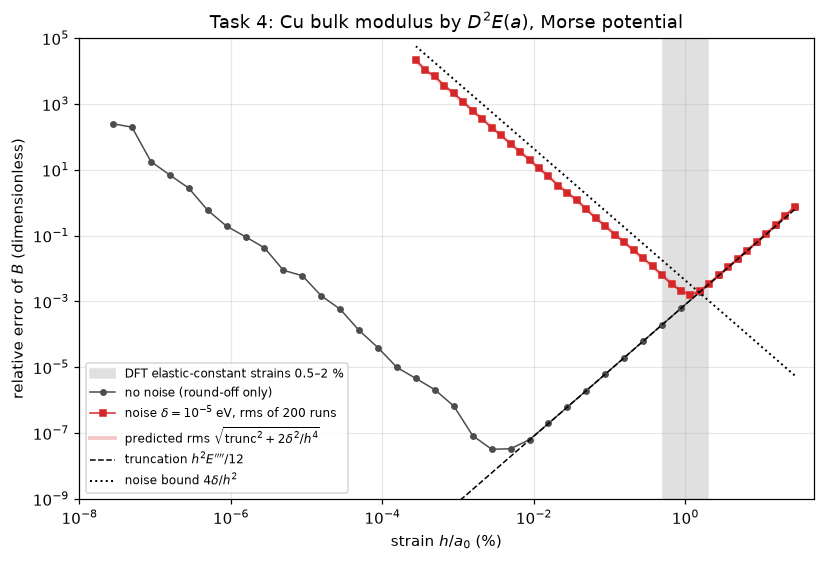

In [23]:
strain = lambda h: h / a0 * 100                        # %
fig, ax = plt.subplots(figsize=(7.6, 5.2))
ax.axvspan(0.5, 2.0, color='0.88', zorder=0, label='DFT elastic-constant strains 0.5–2 %')
ax.loglog(strain(Hb), abs(rel_b), 'o-', ms=3.5, lw=1, color='0.3', label='no noise (round-off only)')
ax.loglog(strain(Hn), rms5 / B, 's-', ms=3.5, lw=1, color='C3', label=r'noise $\delta = 10^{-5}$ eV, rms of 200 runs')
ax.loglog(strain(Hn), pred5 / B, '-', lw=2.5, color='C3', alpha=0.25, label=r'predicted rms $\sqrt{\mathrm{trunc}^2 + 2\delta^2/h^4}$')
ax.loglog(strain(Hb), Hb**2 * E4 / 12 / E2, 'k--', lw=1, label=r"truncation $h^2E''''/12$")
ax.loglog(strain(Hn), 4 * 1e-5 / Hn**2 / E2, 'k:', lw=1.3, label=r'noise bound $4\delta/h^2$')
ax.set_xlim(1e-8, 50)
ax.set_ylim(1e-9, 1e5)
ax.set_xlabel(r'strain $h/a_0$ (%)')
ax.set_ylabel(r'relative error of $B$ (dimensionless)')
ax.set_title('Task 4: Cu bulk modulus by $D^2E(a)$, Morse potential')
ax.legend(loc='lower left', fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'fig4_bulk_modulus.png')
plt.show()

### (d) Validation: comparison with experiment

In [24]:
rows = [('a0 (Å)', a0, 3.615), ('cohesive energy -E(a0) (eV/atom)', -E0, 3.49), ('B (GPa)', B, 137.0),
        ('unrelaxed vacancy E_v^f = -E(a0) (eV)', -E0, 1.28)]
print(f'{"quantity":40} {"Morse":>9} {"exp.":>8} {"rel. diff":>10}')
for name, model, exp in rows:
    print(f'{name:40} {model:9.4f} {exp:8.3f} {(model - exp) / exp:+10.2%}')
print('\nfitted by Girifalco & Weizer: a0, cohesive energy, compressibility -> the first three agree by construction.')

record('4d', 'a0 vs exp. 3.615 Å', a0, 3.615, 'experiment', '-0.24 %')
record('4d', 'cohesive energy vs exp. 3.49 eV', -E0, 3.49, 'experiment', '+1.5 %')
record('4d', 'B vs exp. 137 GPa', B, 137.0, 'experiment', '+1.9 %')
record('4d', 'vacancy E_v^f vs exp. 1.28 eV', -E0, 1.28, 'experiment', '+177 %')

quantity                                     Morse     exp.  rel. diff
a0 (Å)                                      3.6064    3.615     -0.24%
cohesive energy -E(a0) (eV/atom)            3.5429    3.490     +1.51%
B (GPa)                                   139.6270  137.000     +1.92%
unrelaxed vacancy E_v^f = -E(a0) (eV)       3.5429    1.280   +176.79%

fitted by Girifalco & Weizer: a0, cohesive energy, compressibility -> the first three agree by construction.


### (e) Optional: re-selecting the neighbours "within r_c = 10 Å" for every a

How it is decomposed:
- The same 10 Å sphere fixed at a₀ (`s_cut`) is a smooth model; its analytic B is called B_cut.
- E(a) with re-selected neighbours equals this smooth model minus the shells that have left the sphere at a ± h.
- So every B splits into: B_cut + the exact truncation error + the term from crossing the jump.

In [25]:
s_all = fcc_neighbours(4.0)                            # 4 a > 10 Å for every a near a0
Er = lambda a: energy_rescreened(a, s_all, rc=10.0)
s_cut = s[s * a0 <= 10.0]
B_cut = bulk_modulus(energy(a0, s_cut, 2), a0)
print(f'E(a0), rebuilt list r_c = 10 Å = {Er(a0):.6f} eV;  minus (a): {Er(a0) - E0:+.4e} eV')
print(f'10 Å sphere frozen at a0: {len(s_cut)} sites, analytic B_cut = {B_cut:.4f} GPa ({B_cut / B - 1:+.2%} vs (a)),'
      f" E'(a0) = {energy(a0, s_cut, 1):+.2e} eV/Å (a0 is not its equilibrium)")

rad_all, cnt_all = fcc_shells(s_all)
jumps = []
print('\njumps of E(a) for |a - a0| <= 0.1 Å (shell leaves the 10 Å sphere at a = 10/|s|):')
for r_, n_ in zip(rad_all, cnt_all):
    a_j = 10.0 / r_
    if abs(a_j - a0) <= 0.1:
        size = Er(a_j + 1e-9) - Er(a_j - 1e-9)
        jumps.append((a_j, r_, n_, size))
        print(f'  a = {a_j:.4f} Å  (|s|^2 = {r_**2:.1f}, {n_} sites): jump {size:+.4e} eV;  (1/2) n |phi(10 Å)| = {-0.5 * n_ * phi(10.0):.4e} eV')

print('\n  h (Å)   B, rebuilt (GPa)   B_cut + exact trunc. + jump term = prediction')
B_rc = {}
for h in (0.05, 0.02, 0.01):
    B_rc[h] = bulk_modulus(second(Er, a0, h), a0)
    trunc = bulk_modulus(second_difference_error(a0, h, s_cut), a0)
    jump_term = 0.0
    for a_j, r_, n_, _ in jumps:
        if a0 < a_j < a0 + h:                          # shell inside the frozen sphere, already gone at a0 + h
            jump_term -= bulk_modulus(0.5 * n_ * phi((a0 + h) * r_) / h**2, a0)
        if a0 - h < a_j < a0:                          # shell outside the frozen sphere, already in at a0 - h
            jump_term += bulk_modulus(0.5 * n_ * phi((a0 - h) * r_) / h**2, a0)
    pred = B_cut + trunc + jump_term
    print(f'  {h:<6}   {B_rc[h]:12.4f}        {B_cut:.4f} + {trunc:.4f} + {jump_term:.4f} = {pred:.4f}'
          f'   (rel. diff {abs(B_rc[h] / pred - 1):.0e};  {B_rc[h] / B - 1:+.2%} vs (a))')

record('4e', 'E(a0) rebuilt minus (a) (eV)', Er(a0) - E0, None, '', '+1.6e-03')
record('4e', 'B rebuilt, h = 0.05 Å (GPa)', B_rc[0.05], None, '', '148.27')
record('4e', 'B rebuilt, h = 0.02 Å (GPa)', B_rc[0.02], B_cut + bulk_modulus(second_difference_error(a0, 0.02, s_cut), a0),
       'B_cut + exact trunc.', '140.22')
record('4e', 'B rebuilt, h = 0.01 Å (GPa)', B_rc[0.01], B_cut + bulk_modulus(second_difference_error(a0, 0.01, s_cut), a0),
       'B_cut + exact trunc.', '140.19')
for a_j, r_, n_, size in jumps:
    record('4e', f'jump at a = 10/sqrt({r_**2:.1f}) Å (eV)', size, -0.5 * n_ * phi(10.0), '(1/2) n |phi(10 Å)|',
           '1.0e-03' if n_ == 48 else '2.5e-04')

E(a0), rebuilt list r_c = 10 Å = -3.541242 eV;  minus (a): +1.6128e-03 eV
10 Å sphere frozen at a0: 368 sites, analytic B_cut = 140.1798 GPa (+0.40% vs (a)), E'(a0) = -6.70e-03 eV/Å (a0 is not its equilibrium)

jumps of E(a) for |a - a0| <= 0.1 Å (shell leaves the 10 Å sphere at a = 10/|s|):
  a = 3.6515 Å  (|s|^2 = 7.5, 48 sites): jump +1.0150e-03 eV;  (1/2) n |phi(10 Å)| = 1.0150e-03 eV
  a = 3.5355 Å  (|s|^2 = 8.0, 12 sites): jump +2.5376e-04 eV;  (1/2) n |phi(10 Å)| = 2.5376e-04 eV

  h (Å)   B, rebuilt (GPa)   B_cut + exact trunc. + jump term = prediction
  0.05         148.2685        140.1798 + 0.2175 + 7.8712 = 148.2685   (rel. diff 7e-14;  +6.19% vs (a))
  0.02         140.2146        140.1798 + 0.0348 + 0.0000 = 140.2146   (rel. diff 1e-12;  +0.42% vs (a))
  0.01         140.1885        140.1798 + 0.0087 + 0.0000 = 140.1885   (rel. diff 1e-12;  +0.40% vs (a))


**Reading the results:**

- **(a) Equilibrium.** a₀, E(a₀), E'' and E⁗ all agree with 05; the analytic derivatives are also verified independently by the complex step, with a relative difference of 0 (agreement to the last digit).
  - Raising the neighbour cutoff from 5.5 to 7 changes E(a₀) by −1.14×10⁻⁸ eV, **slightly more** than the 10⁻⁸ required by the assignment. This is the genuine tail of the lattice sum: the continuum estimate is −1.11×10⁻⁸ eV, and raising the cutoff all the way to 10 converges to −1.145×10⁻⁸ eV.
  - The effect of this cutoff on B is only 10⁻⁷ (relative), and the finite differences of (b) and the analytic B use the same list, so the verification is unaffected. See point 1 of the last section.
- **(b) No noise (verification).** Truncation slope 2.000. $(B_{FD} - B)/h^2$ tends, as h → 0, to the theoretical coefficient $(4/9a_0)(E''''/12) \times 160.2 = 86.149$ GPa/Å². It matches the exact truncation error from the sinh closed form to 11 digits at h = 0.1 Å and to 7 digits at h = 0.01 Å; the remaining difference is round-off. At h = 0.001 Å the round-off already changes the 3rd digit (86.21). The minimum is at h ≈ 10⁻⁴ Å with a relative error of 3×10⁻⁸; the theoretical h\* is 1.6×10⁻⁴ Å. Here δ is only the round-off of the energy, ε|E| ≈ 8×10⁻¹⁶ eV.
- **(c) With noise.** δ = 10⁻⁵ eV is 10 orders of magnitude larger than ε|E|, and h\* ∝ δ^{1/4}, so it moves 10^{10/4} ≈ 300 times to the right, to about 0.04 Å, i.e. a strain of 1.2%.
  - The rms of the 200 simulations matches the prediction "truncation² + 2δ²/h⁴" within ±10%, which is the statistical scatter of only 200 samples.
  - The measured optimum h = 0.042 Å agrees with $h^*_{\rm rms}$ = 0.042 Å; the bound model of the lecture notes gives 0.055 Å, a little too large, because it assumes that all four δ take their worst values with the same sign.
  - For δ = 10⁻⁴ eV (the VASP default), the optimum h is 0.075 Å (a strain of 2.1%).
  - Conversely, at h = 0.001 Å (a strain of 0.03%) the noise makes B 200% wrong. "Use a smaller h when the noise is large" is exactly backwards.
- **Sholl & Steckel Table 5.1** is the same V. When the displacement is too small (0.001 Å), the DFT energy noise dominates and the frequency is inaccurate; when it is too large (≥ 0.06 Å), truncation (anharmonicity) dominates and the frequency keeps rising; in between, 0.005–0.04 Å, it is stable. The noisy curves of figure 4 are the same: slope −2 on the left arm (noise), +2 on the right arm (truncation), and the minimum at about 1% strain.
- **(d) Validation.** a₀, the cohesive energy and B are all within 2% of experiment, but these three quantities (lattice constant, energy of vaporization, compressibility) are exactly the experimental values Girifalco & Weizer used to fit the three parameters. The agreement only shows that the fit was done correctly; it is not an independent confirmation. A genuine prediction is the vacancy formation energy: Morse gives 3.54 eV, experiment about 1.28 eV, an overestimate by a factor of 2.8. This is **δ_model (model error)**: a pair potential assumes that the strength of each bond does not depend on its environment and leaves out the many-body nature of metallic bonding. No choice of step or neighbour count removes it; it takes a many-body potential such as EAM.
- **(e) Re-selected neighbours.** With r_c = 10 Å there are two jumps within a₀ ± 0.1 Å: at a = 3.6515 Å (48 points, 1.0×10⁻³ eV) and 3.5355 Å (12 points, 2.5×10⁻⁴ eV); their size is exactly ½ n|φ(10 Å)|.
  - h = 0.05 Å crosses the jump at 3.6515 Å, and B is 6% off. To the finite difference, this jump is a "noise" of δ ≈ 10⁻³ eV.
  - h = 0.02 and 0.01 Å do not cross it, and B is 0.4% higher than in (a). Almost all of this 0.4% comes from r_c = 10 Å itself: without the tail beyond 10 Å, B_cut = 140.18 GPa. The actual truncation error of the step is only 0.035 GPa (0.025%). The decomposition above reproduces all three B to a relative 10⁻¹² or better.

## Summary table

- `check`: an independent reference value. It is a theoretical value, a closed form or exact error series, the complex step, or an experimental value (validation only); the `check from` column says which. `rel. diff` is the difference of this run relative to `check`.
  - Rows marked (mag.) are dominated by round-off and are compared only in order of magnitude.
  - Rows marked (bound) are the bounds of the lecture notes; the measured value should be smaller.
- `05`: the value printed in the course's reference solution, for reference only. It usually has only 2–4 significant digits; in a few places it differs from this run, for the reasons in the next section.

In [26]:
print(f'{"task":4}  {"quantity":34} {"this run":>14} {"check":>14}  {"check from":25} {"rel. diff":>9}   {"05":>15}')
print('-' * 128)
for task, name, ours, check, how, ref05 in summary:
    if check is None:
        chk, rd = '', ''
    else:
        chk = f'{check:14.8g}'
        rd = f'{abs(ours):8.1e}*' if check == 0 else f'{abs(ours - check) / abs(check):9.1e}'
    print(f'{task:4}  {name:34} {ours:14.8g} {chk:>14}  {how:25} {rd:>9}   {ref05:>15}')
print('* check value is 0: absolute value shown instead of relative difference')

task  quantity                                 this run          check  check from                rel. diff                05
--------------------------------------------------------------------------------------------------------------------------------
0     loop eps (float64)                   2.220446e-16   2.220446e-16  np.finfo                    0.0e+00   2.220446049250313e-16
0     halvings (float64)                             52             52  theory (52 bits)            0.0e+00                52
0     loop eps (float32)                  1.1920929e-07  1.1920929e-07  2^-23                       0.0e+00     1.1920929e-07
0     np.spacing(1e3)                     1.1368684e-13  1.1368684e-13  2^(9-52)                    0.0e+00          1.14e-13
0     np.spacing(1e6)                     1.1641532e-10  1.1641532e-10  2^(19-52)                   0.0e+00          1.16e-10
0     np.spacing(1e16)                                2              2  2^(53-52)                   0.0e+00  

## Differences from the reference solution (05)

Most numbers in 05 are correct to the digits and tolerances it gives. The points below are not errors in this program; either 05 is not precise enough, or its explanation can be made more precise.

1. **Task 4(a): raising the |s| cutoff from 5.5 to 7 changes E(a₀) by −1.14×10⁻⁸ eV, not about 1.4×10⁻⁹ eV.** This number is in fact slightly larger than the 10⁻⁸ required by the assignment. Three independent pieces of evidence:
   - The first shell beyond 5.5 alone (|s|² = 30.5, 120 points) contributes −3.6×10⁻⁹ eV, already more than the total in 05.
   - The continuum estimate $\tfrac12(4/a^3)\int 4\pi r^2\phi\,dr$ gives −1.11×10⁻⁸ eV.
   - Raising the cutoff to 8 and 10 converges to −1.145×10⁻⁸ eV.

   So the truncation error of the lattice sum at 5.5 is of the order of 10⁻⁸ eV and just misses the threshold of the assignment. Its effect on B, however, is only 1.4×10⁻⁵ GPa (a relative 10⁻⁷), smaller than the error of any finite-difference step. And the finite-difference B and the analytic B use the same list, so the conclusion of the verification is unchanged. To pass the 10⁻⁸ threshold strictly, a cutoff of 6 is enough: from 6 to 7, E(a₀) changes by only 1.2×10⁻⁹ eV.
2. **Task 4(e): the 0.4% by which B at h = 0.02 and 0.01 Å exceeds (a) is not "a bias from truncation".** The truncation error of the step at h = 0.02 Å is only 0.035 GPa (0.025%). The 0.4% comes from r_c = 10 Å itself: dropping the tail of the potential beyond 10 Å amounts to a different model, whose analytic B at a₀ is 140.18 GPa. For this model E' = −6.7×10⁻³ eV/Å ≠ 0 at a₀, so a₀ is not its equilibrium. Adding B_cut, the exact truncation error and the jump term reproduces B for all three h to a relative 10⁻¹² or better.
3. **Task 3: Q\* extrapolated with p = 2 has an error of −1.84×10⁻⁸, 4 times smaller than 05's 7×10⁻⁸.** 05's Q\* = 14.7661355 is extrapolated with p_obs = 1.9997. The error expansion of D₀ has only even powers, so p = 2 is the theoretical value; p_obs deviates from 2 precisely because of the next term, h⁴, and putting it back into the extrapolation formula mixes the effect of h⁴ into the h² term. With p = 2, Q\* is D₅ at h = 1 K, with an error of −1.84×10⁻⁸, in agreement with the predicted $-(h^4/30)U^{(5)} - (h^6/252)U^{(7)}$. That is about 20,000 times better than Q₃, not 5000 times. The error estimate |Q\* − Q₃| = 3.81×10⁻⁴ is the same either way.
4. **Task 1(a): for D₃ at h = 0.001, the 3rd digit of 6.9979×10⁻¹¹ is already round-off.** This program also gives 6.9979×10⁻¹¹, the same as 05. But the exact truncation error is 7.0105×10⁻¹¹, and the difference of 1.3×10⁻¹³ is round-off (bound 2ε|f|/h = 3.7×10⁻¹³). 05 says that "4–5 significant digits should all agree" in this table, which does not hold for this entry: with another implementation of sin, the 3rd digit may differ. Every other entry matches the exact truncation error to 6 digits or more.
5. **Task 0, step 4: at x = 10⁻⁸, cos x is rounded to 1, and the comparison is with the spacing below 1.** 05 and the lecture notes say that 1 − cos x = 5×10⁻¹⁷ is "smaller than half a spacing near 1, 1.1×10⁻¹⁶". 1.1×10⁻¹⁶ is half the spacing ε **above** 1. cos x approaches 1 from below, and the spacing below 1 is ε/2 = 1.1×10⁻¹⁶, half of which is 5.55×10⁻¹⁷. 5×10⁻¹⁷ is only 10% smaller than that: once x exceeds √(ε/2) = 1.05×10⁻⁸, cos x is no longer 1.
6. **Numbers in the round-off region (within 05's tolerances, just different).** These are all dominated by round-off, and 05 itself only checks their order of magnitude:
   - D₀ slope in the round-off region: −1.01 here, −1.04 in 05.
   - h with the smallest D₅ error: 3.2×10⁻⁴ here, 5.6×10⁻⁴ in 05.
   - Task 4(b), optimal h without noise: 1.0×10⁻⁴ Å here, about 2×10⁻⁴ Å in 05.
7. **Additions (not errors in 05).** 05 gives only the bound model of the lecture notes, h\* = 0.055 Å, and "the rms optimum is about 0.04 Å". Here the rms model is derived: $h^*_{\rm rms} = (12\sqrt2\,\delta/|E''''|)^{1/4}$ = 0.042 Å (δ = 10⁻⁵ eV) and 0.075 Å (δ = 10⁻⁴ eV), in agreement with the 200 simulations. The −1.110 of D² at h = 10⁻⁸ also has an exact origin: it is exactly −1 spacing/h² (Task 2(a)).